# **INSTITUTO TECNOLÓGICO DE COSTA RICA**
### **CURSO: MÉTODOS NUMÉRICOS**
---
## **LABORATORIO 1:**
# **SIMULACIÓN BIDIMENSIONAL Y CONTROL CINEMÁTICO DE UN BRAZO ROBÓTICO PLANO DE TRES ARTICULACIONES (3-DOF) MEDIANTE NEWTON-RAPHSON MULTIVARIABLE**

---
### **Información del Equipo de Trabajo:**
- **Coordinador:** Errol Pérez Salas
- **Integrantes (Solo 3):**
  1. Errol Pérez Salas (Coordinador de Proyecto, Modelado Numérico y Algoritmo Newton-Raphson. Versión preliminar)
  2. Esteban Chavarría (Validación de Jacobianos Analíticos y verificación de las condiciones iniciales. Animaciones Gif y Mapeo posiciones permitidas por condición.)
  3. Amilcar Ernesto Rodríguez Magaña (Revisión del modelo preliminar, revicion del codigo y comentarios y revisar animaciones GIF.)


### **Profesor del Curso:**
- Jeffry Chavarría Molina

### **Periodo Lectivo:**
- II Semestre 2026
---


## **1. Objetivos del Proyecto**

### **1.1. Objetivo General**
Desarrollar, validar e implementar un laboratorio computacional integral en Python (ejecutable en Google Colab) para modelar, resolver cinemáticamente y simular dinámicamente el movimiento continuo de un brazo robótico planar de tres eslabones rotacionales (3-DOF), formulando el problema de cinemática inversa como un sistema no lineal de 3 ecuaciones con 3 incógnitas resuelto numéricamente mediante el método de Newton-Raphson multivariable bajo 5 condiciones auxiliares distintas.

### **1.2. Objetivos Específicos**
1. **Modelar formalmente la cinemática directa** del manipulador plano determinando las posiciones cartesianas de todas sus articulaciones.
2. **Formular analíticamente los 5 sistemas no lineales** cerrados incorporando las ecuaciones auxiliares para resolver la redundancia cinemática articular.
3. **Construir explícitamente las 5 matrices Jacobianas analíticas** verificando su exactitud contra esquemas de diferencias finitas y analizando sus singularidades cinemáticas.
4. **Implementar el algoritmo de Newton-Raphson multivariable robusto** con criterios de parada, control de condicionamiento numérico y un banco sistemático de semillas de contingencia ante singularidades.
5. **Programar la función base NR_Un_Punto y el módulo de trayectoria **, garantizando inicio y fin en la postura de reposo, interpolación simultánea sin saltos de $2\pi$, y generación de animaciones GIF.
6. **Fases obligatorias:**
   - **Fase I:** Comparativa de trayectorias, residuos y sensibilidad inicial sobre la secuencia compatible $P$.
   - **Fase II:** Clasificación de incompatibilidad y política de continuidad sobre la secuencia $Q$.
   - **Fase III:** Construcción y estudio comparativo de los mapas del espacio de trabajo en una cuadrícula cartesiana.


## Declaración de uso responsable de Inteligencia Artificial

Para el desarrollo de este proyecto se utilizaron herramientas de Inteligencia Artificial como apoyo durante el proceso de elaboración y revisión del trabajo.

Se utilizó **Gemini Flash 3.8** para la verificación simbólica de los Jacobianos, revisión y organización del código, así como para la identificación y corrección de errores.

También se utilizó **Antigravity** como espacio de trabajo para consultar y organizar documentación relacionada con temas de ingeniería y matemática.

Adicionalmente, se utilizó **ChatGPT (OpenAI)** como apoyo para la revisión del código, identificación de errores, explicación de conceptos relacionados con el método de Newton-Raphson multivariable y revisión de la estructura del proyecto en Google Colab.

Las respuestas y sugerencias proporcionadas por estas herramientas fueron revisadas, adaptadas y verificadas por los integrantes del equipo. El equipo comprendió y validó los procedimientos utilizados y mantiene la responsabilidad académica sobre el contenido, resultados, código y conclusiones presentadas en este proyecto.


## **3. Bitácora de Trabajo y Distribución de Responsabilidades**

A continuación se detalla el cronograma de reuniones, distribución de roles y metas alcanzadas por el equipo de cuatro integrantes:

| Fecha | Asistentes | Acuerdos y Tareas Asignadas | Responsable | Meta / Evidencia |
| :---: | :---: | :--- | :---: | :--- |
| **20/09/2026** | Todos | - Primer acercamiento del problema y asignación de roles. | Esteban Chavarría. | Primer acercamiento al problema, creación de áreas de trabajo (2 colabs, antigravity y Whatsappxº). |
| **23/09/2026** | Todos | - Formulación de un modelo preeliminar con las restricciones y puntos de desplazamiento .<br>- Cálculo manual y simbólico de los 5 Jacobianos analíticos.<br>- Diseño del algoritmo Newton-Raphson multivariable. | Errol |Código funcional con convergencia en varios puntos y gif. |
| **2/10/2026** | Todos | -Revisión del modelo preeliminar.<br>-Implementación del bloque 11 comparativo de las 5 ecuaicones auxiliares<br>- Generación de animaciones GIF en bucle infinito. | Amilcar | Código funcional de simulación dinámica con colores en cada brazo, dirección del movimiento y residuo en el plot. |
| **5/10/2026** | Todos | -Implementación del bloque 9 de análisis de sensibilidad incial.<br>- Nuevo plot para la visualización de las áreas de movimiento válido. | Todos | Tabla completa de las 20 combinaciones de la Secuencia Q y gráficas comparativas. |
| **7/10/2026** | Todos | - Ejecución de Fase III: Mapeo del espacio de trabajo (Alternativa 1, malla 101x101).<br>- Análisis geométrico de simetrías, fronteras y regiones vacías.<br>- Consolidación del informe final en Google Colab y preparación de defensa oral. | Todos | Cuaderno de Google Colab integrado, 5 mapas individuales y figura comparativa unificada. |

## **4. Modelo Geométrico del Brazo Robótico Plano de 3-DOF**

El sistema bajo estudio corresponde a un manipulador robótico serial que opera en el plano cartesiano $\mathbb{R}^2$. Está constituido por una base fija en el origen $(0,0)$ y una cadena cinemática abierta de tres eslabones rígidos de longitudes $l_1, l_2, l_3 > 0$, interconectados mediante tres pares cinemáticos de revolución (articulaciones rotacionales) cuyos ángulos relativos se denotan por $\theta_1, \theta_2, \theta_3$.
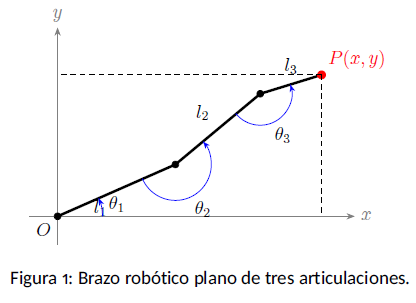
### **4.1. Cinemática Directa de Posición**
Definiendo los ángulos acumulados con respecto a la horizontal:
$$\theta_{1} = \theta_1$$
$$\theta_{12} = \theta_1 + \theta_2$$
$$\theta_{123} = \theta_1 + \theta_2 + \theta_3$$

Las posiciones cartesianas de cada vértice articular se expresan como:
1. **Base fija:**
   $$P_0 = (x_0, y_0) = (0, 0)$$
2. **Primera articulación (Codo 1):**
   $$P_1 = (x_1, y_1) = (l_1 \cos\theta_1, \; l_1 \sin\theta_1)$$
3. **Segunda articulación (Codo 2 / Muñeca):**
   $$P_2 = (x_2, y_2) = (x_1 + l_2 \cos\theta_{12}, \; y_1 + l_2 \sin\theta_{12})$$
4. **Efector final (Extremo operativo):**
   $$P_3 = (x_3, y_3) = (x_2 + l_3 \cos\theta_{123}, \; y_2 + l_3 \sin\theta_{123}) = (x, y)$$

Expandiendo directamente, la posición cartesiana $(x, y)$ del efector final en función exclusiva del vector de coordenadas generalizadas $\theta = [\theta_1, \theta_2, \theta_3]^T$ es:
$$x(\theta) = l_1 \cos(\theta_1) + l_2 \cos(\theta_1 + \theta_2) + l_3 \cos(\theta_1 + \theta_2 + \theta_3)$$
$$y(\theta) = l_1 \sin(\theta_1) + l_2 \sin(\theta_1 + \theta_2) + l_3 \sin(\theta_1 + \theta_2 + \theta_3)$$

### **4.2. Límites Físicos del Espacio de Trabajo General (Sin Restricciones Auxiliares)**
Para longitudes genéricas $l_1, l_2, l_3$, la distancia radial $r = \sqrt{x^2 + y^2}$ del efector final al origen está acotada estrictamente por la desigualdad del polígono articular:
- **Alcance máximo exterior:** Configuración totalmente extendida ($\theta_2 = 0, \theta_3 = 0$):
  $$r_{max} = l_1 + l_2 + l_3$$
- **Alcance mínimo interior:** Se produce cuando el eslabón más largo se pliega contra los otros dos:
  $$r_{min} = \max\left(0, \; l_{max} - \sum_{i
eq max} l_i\right)$$
  Para el caso particular de eslabones unitarios ($l_1 = l_2 = l_3 = 1$):
  $$r_{max} = 1 + 1 + 1 = 3, \quad r_{min} = \max(0, \; 1 - (1 + 1)) = 0$$
  Por ende, el espacio de trabajo general cubre el disco completo de radio 3 centrado en el origen: $0 \le x^2 + y^2 \le 9$.


## **5. Planteamiento Matemático de los Cinco Sistemas No Lineales**

El problema de cinemática inversa consiste en determinar la configuración articular $\theta = [\theta_1, \theta_2, \theta_3]^T$ necesaria para ubicar el efector final en una coordenada cartesiana objetivo $(x, y)$ dada.

Dado que existen **dos ecuaciones de posición** y **tres incógnitas articulares**, el sistema posee un grado de libertad excedente (redundancia cinemática intrínseca). Por tanto, existe una infinidad de posturas articulares capaces de alcanzar el mismo punto cartesiano. Para determinar una solución única y bien condicionada, se introduce una **tercera ecuación auxiliar** $F_3^{(s)}(\theta) = 0$, cerrando el sistema en una formulación cuadrada de dimensión $3 \times 3$:

$$F(\theta) = \begin{bmatrix} F_1(\theta) \\ F_2(\theta) \\ F_3^{(s)}(\theta) \end{bmatrix} = \begin{bmatrix} 0 \\ 0 \\ 0 \end{bmatrix}$$

donde:
$$F_1(\theta) = l_1 \cos(\theta_1) + l_2 \cos(\theta_1 + \theta_2) + l_3 \cos(\theta_1 + \theta_2 + \theta_3) - x = 0$$
$$F_2(\theta) = l_1 \sin(\theta_1) + l_2 \sin(\theta_1 + \theta_2) + l_3 \sin(\theta_1 + \theta_2 + \theta_3) - y = 0$$

---
### **5.1. Interpretación Física y Geométrica de las Cinco Opciones Auxiliares**

#### **1. Opción A: Orientación Horizontal del Efector**
$$F_3^{(A)}(\theta) = \theta_1 + \theta_2 + \theta_3 = 0$$
- **Significado geométrico:** La orientación absoluta del tercer eslabón respecto al eje horizontal es nula ($\phi = 0$). El tercer eslabón siempre apunta horizontalmente hacia la derecha ($+X$).
- **Implicación cinemática:** La posición de la muñeca queda fija en $(x_w, y_w) = (x - l_3, y)$. La subcadena cinemática de dos eslabones $(l_1, l_2)$ debe alcanzar dicho punto de muñeca.
- **Condición de compatibilidad:** Para $l_1=l_2=l_3=1$, se exige que $(x-1)^2 + y^2 \le (l_1+l_2)^2 = 4$. Esto restringe el espacio alcanzable a un círculo de radio 2 desplazado a $(1, 0)$.

#### **2. Opción B: Orientación Vertical del Efector**
$$F_3^{(B)}(\theta) = \theta_1 + \theta_2 + \theta_3 - \frac{\pi}{2} = 0$$
- **Significado geométrico:** La orientación absoluta del efector es vertical ascendente ($\phi = \pi/2$, paralelo al eje $+Y$).
- **Implicación cinemática:** La muñeca se ubica forzosamente en $(x_w, y_w) = (x, y - l_3)$.
- **Condición de compatibilidad:** Para $l_1=l_2=l_3=1$, se requiere $x^2 + (y - 1)^2 \le 4$. Corresponde a un círculo de radio 2 centrado en $(0, 1)$.

#### **3. Opción C: Tercer Eslabón Alineado con el Segundo**
$$F_3^{(C)}(\theta) = \theta_3 = 0$$
- **Significado geométrico:** La tercera articulación se mantiene completamente recta. El segundo y tercer eslabón forman un único segmento rígido de longitud equivalente $L_{23} = l_2 + l_3$.
- **Implicación cinemática:** El robot se reduce a un manipulador planar de 2 eslabones con longitudes $l_1$ y $(l_2+l_3)$.
- **Condición de compatibilidad:** Para $l_1=1$ y $L_{23}=2$, el alcance está acotado por:
  $$|l_1 - L_{23}| \le \sqrt{x^2+y^2} \le l_1 + L_{23} \implies 1 \le \sqrt{x^2+y^2} \le 3$$
  **Se crea un hueco central interior inaccesible:** Ningún punto con radio $r < 1$ puede ser alcanzado, ya que el brazo no puede flexionarse lo suficiente.

#### **4. Opción D: Ángulos Relativos Segundo y Tercero Iguales**
$$F_3^{(D)}(\theta) = \theta_2 - \theta_3 = 0 \iff \theta_3 = \theta_2$$
- **Significado geométrico:** La flexión de la segunda y tercera articulación es simétrica.
- **Implicación cinemática:** El brazo adopta una curvatura articular homogénea.
- **Condición de compatibilidad:** Factorizando la cinemática directa con $\theta_2 = \theta_3$:
  $$x + i y = e^{i(\theta_1+\theta_2)} \left[ 1 + 2\cos\theta_2\right]$$
  La distancia radial resultante es $r = |1 + 2\cos\theta_2|$. Al variar $\theta_2 \in [0, \pi]$, el término $1+2\cos\theta_2$ barre continuamente todos los valores entre $-1$ y $3$. En consecuencia, **la Opción D puede cubrir la totalidad del disco cartesiano $r \in [0, 3]$**, conservando el 100% del alcance del robot general.

#### **5. Opción E: Orientación Tangencial Respecto al Origen**
$$F_3^{(E)}(\theta) = \theta_1 + \theta_2 + \theta_3 - \alpha(x,y) - \frac{\pi}{2} = 0$$
donde:
$$\alpha(x, y) = \begin{cases} \text{atan2}(y, x), & (x, y)
eq (0, 0) \\ 0, & (x, y) = (0, 0) \end{cases}$$
- **Significado geométrico:** El tercer eslabón se mantiene perpendicular al vector de posición radial $(x, y)$, es decir, tangente a la circunferencia centrada en el origen que pasa por el punto objetivo.
- **Implicación cinemática:** Formando el triángulo rectángulo entre el origen, la muñeca y el efector: la distancia a la muñeca cumple estrictamente $\|P_2\|^2 = r^2 + l_3^2$.
- **Condición de compatibilidad:** Para que los eslabones 1 y 2 alcancen la muñeca:
  $$\|P_2\|^2 \le (l_1+l_2)^2 \implies r^2 + l_3^2 \le (l_1+l_2)^2 \implies r^2 \le (1+1)^2 - 1^2 = 3 \implies r \le \sqrt{3} \approx 1.732$$
  **El espacio de trabajo queda estrictamente limitado a un círculo de radio $\sqrt{3}$**. Cualquier punto con distancia radial $r > \sqrt{3}$ es matemáticamente incompatible con la Opción E.

### **5.2. Corte de Rama de $\text{atan2}$ y Desenvolvimiento Angular (`unwrap`)**
En la Opción E, la función $\text{atan2}(y, x)$ presenta una discontinuidad de salto de $2\pi$ a lo largo del semieje real negativo ($x < 0, y \to 0^\pm$). Si los ángulos articulares se interpolaran linealmente sin corregir este corte modular, el brazo ejecutaría rotaciones artificiales completas de $360^\circ$. Para garantizar una trayectoria suave y físicamente continua, se aplica la corrección de camino angular mínimo:
$$\Delta\theta_i = (\theta_{i, objetivo} - \theta_{i, actual} + \pi) \pmod{2\pi} - \pi$$

## **6. Construcción Explícita de las Cinco Matrices Jacobianas Analíticas**

La matriz Jacobiana $J(\theta) \in \mathbb{R}^{3 \times 3}$ representa la matriz de derivadas parciales de primer orden del sistema vectorial no lineal $F(\theta)$:

$$J(\theta) = \begin{bmatrix}
\frac{\partial F_1}{\partial \theta_1} & \frac{\partial F_1}{\partial \theta_2} & \frac{\partial F_1}{\partial \theta_3} \[6pt]
\frac{\partial F_2}{\partial \theta_1} & \frac{\partial F_2}{\partial \theta_2} & \frac{\partial F_2}{\partial \theta_3} \[6pt]
\frac{\partial F_3^{(s)}}{\partial \theta_1} & \frac{\partial F_3^{(s)}}{\partial \theta_2} & \frac{\partial F_3^{(s)}}{\partial \theta_3}
\end{bmatrix}$$

### **6.1. Filas Comunes: Derivadas de Posición Cartesiana**
Aplicando la regla de la cadena sobre $F_1$ y $F_2$, denotando $\theta_{12} = \theta_1 + \theta_2$ y $\theta_{123} = \theta_1 + \theta_2 + \theta_3$:

- **Primera fila (Derivadas de $F_1$ respecto a $[\theta_1, \theta_2, \theta_3]$):**
  $$\frac{\partial F_1}{\partial \theta_1} = -l_1 \sin\theta_1 - l_2 \sin\theta_{12} - l_3 \sin\theta_{123}$$
  $$\frac{\partial F_1}{\partial \theta_2} = -l_2 \sin\theta_{12} - l_3 \sin\theta_{123}$$
  $$\frac{\partial F_1}{\partial \theta_3} = -l_3 \sin\theta_{123}$$

- **Segunda fila (Derivadas de $F_2$ respecto a $[\theta_1, \theta_2, \theta_3]$):**
  $$\frac{\partial F_2}{\partial \theta_1} = l_1 \cos\theta_1 + l_2 \cos\theta_{12} + l_3 \cos\theta_{123}$$
  $$\frac{\partial F_2}{\partial \theta_2} = l_2 \cos\theta_{12} + l_3 \cos\theta_{123}$$
  $$\frac{\partial F_2}{\partial \theta_3} = l_3 \cos\theta_{123}$$

### **6.2. Tercera Fila: Gradiente de la Ecuación Auxiliar $\nabla F_3^{(s)}$**
- **Opciones A, B y E:**
  Dado que en la Opción E los términos $\alpha(x, y)$ y $\pi/2$ dependen de las coordenadas del punto objetivo y son constantes respecto a $\theta$:
  $$\nabla F_3^{(A)} =\nabla F_3^{(B)} =\nabla F_3^{(E)} = \begin{bmatrix} 1 & 1 & 1 \end{bmatrix}$$
- **Opción C ($F_3^{(C)} = \theta_3 = 0$):**
  $$\nabla F_3^{(C)} = \begin{bmatrix} 0 & 0 & 1 \end{bmatrix}$$
- **Opción D ($F_3^{(D)} = \theta_2 - \theta_3 = 0$):**
  $$\nabla F_3^{(D)} = \begin{bmatrix} 0 & 1 & -1 \end{bmatrix}$$

### **6.3. Análisis de Singularidades Cinemáticas ($\det(J) = 0$)**
Una configuración es cinemáticamente singular si las filas de $J(\theta)$ pierden independencia lineal ($\det(J) = 0$), imposibilitando invertir la matriz o resolver el sistema lineal de Newton.
- Para las opciones A, B y E, al restar la fila 3 escalada o analizar la submatriz de posición de la muñeca, el determinante se anula cuando $\sin(\theta_2) = 0$ (es decir, $\theta_2 = 0$ o $\theta_2 = \pi$), correspondiente a la alineación del primer y segundo eslabón.
- Específicamente, en la postura totalmente extendida de reposo $(\theta_1, \theta_2, \theta_3) = (0, 0, 0)$, el brazo se encuentra sobre una frontera de singularidad. Por esta razón matemática fundamental, **no se debe utilizar $(0, 0, 0)$ como semilla inicial directa de Newton-Raphson**, sino una semilla cambiada o proveniente del punto previo.


## **7. Explicación del Método de Newton-Raphson Multivariable Aplicado al Problema**

Para aproximar la solución del sistema no lineal $F(\theta) = 0$, se efectúa una aproximación en serie de Taylor de primer orden alrededor de la estimación actual $\theta^{(k)}$:
$$F(\theta^{(k)} + \Delta\theta) \approx F(\theta^{(k)}) + J(\theta^{(k)}) \Delta\theta = 0$$

Despejando el vector de corrección articular $\Delta\theta^{(k)}$:
$$J(\theta^{(k)}) \Delta\theta^{(k)} = -F(\theta^{(k)})$$

En cada iteración $k = 0, 1, 2, \dots$:
1. Se evalúa el vector de residuos $F(\theta^{(k)})$ y se calcula su norma euclídea $\|F(\theta^{(k)})\|_2$.
2. Se evalúa la matriz Jacobiana analítica $J(\theta^{(k)})$ y se verifica que su número de condición no exceda $10^{12}$ para evitar inestabilidades por singularidad.
3. Se resuelve el sistema lineal de ecuaciones algebraicas mediante factorización LU o eliminación gaussiana (`np.linalg.solve`).
4. Se actualiza el vector de ángulos:
   $$\theta^{(k+1)} = \theta^{(k)} + \Delta\theta^{(k)}$$
5. **Criterios de Parada y Tolerancias:**
   El proceso finaliza con éxito si se satisface cualquiera de las siguientes condiciones de convergencia:
   $$\|\Delta\theta^{(k)}\|_\infty < \varepsilon \quad \text{o} \quad \|F(\theta^{(k+1)})\|_2 < \varepsilon$$
   con $\varepsilon = 10^{-7}$ y un número máximo de iteraciones $K_{max} = 100$.

### **7.1. Estrategia Multi-Semilla **
Si la suposición inicial elegida produce un Jacobiano singular ($\det(J) \approx 0$) o no converge dentro de las iteraciones máximas, el algoritmo ejecuta de inmediato una secuencia:
1. Suposición inicial preferente (configuración del punto anterior).
2. Cuatro perturbaciones locales simétricas: $\theta \pm [\delta, -\delta, \delta]$ con $\delta \in \{0.25, 0.6\}$.
3. Banco global de 16 configuraciones canónicas bien condicionadas (codo arriba, codo abajo, simetrías reflejadas).
Esta arquitectura garantiza una convergencia determinista y elimina falsos negativos numéricos.


## **8. Implementación Computacional en Python**

Se presentan las celdas de código completas estructuradas y documentadas línea por línea.


In [ ]:
# ==============================================================================
# IMPORTACIÓN DE LIBRERÍAS ESTÁNDAR
# ==============================================================================
import os
import io
import time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Image as IPImage, display as ip_display

# ==============================================================================
# FUNCIONES AUXILIARES DE TRIGONOMETRÍA Y CINEMÁTICA DIRECTA
# ==============================================================================

def wrap_to_pi(angle):
    """Normaliza ángulos al rango semiabierto (-pi, pi].

    Esta función evita problemas de discontinuidad en las articulaciones rotacionales
    reoduciendo cualquier rotación acumulada a su equivalente más simple.
    """
    return (angle + np.pi) % (2.0 * np.pi) - np.pi

def menor_diferencia_angular(theta_destino, theta_origen):
    """Calcula el desplazamiento angular más corto evitando saltos de 2*pi (unwrap).

    Permite que los motores del brazo robótico sigan trayectorias suaves en lugar de
    dar giros bruscos de 360 grados al cruzar el límite del corte de rama.
    """
    diff = np.array(theta_destino, dtype=float) - np.array(theta_origen, dtype=float)
    return (diff + np.pi) % (2.0 * np.pi) - np.pi

def cinematica_directa(theta, l1, l2, l3):
    """Calcula las coordenadas de Base, Articulación 1, Articulación 2 y Efector Final.

    Aplica las ecuaciones trigonométricas directas usando los ángulos acumulados
    respecto a la horizontal (theta_1, theta_12, theta_123) para mapear el estado
    articular al espacio cartesiano de cada eslabón.
    """
    t1, t2, t3 = theta
    t12 = t1 + t2
    t123 = t1 + t2 + t3
    x0, y0 = 0.0, 0.0
    x1, y1 = l1 * np.cos(t1), l1 * np.sin(t1)
    x2, y2 = x1 + l2 * np.cos(t12), y1 + l2 * np.sin(t12)
    x3, y3 = x2 + l3 * np.cos(t123), y2 + l3 * np.sin(t123)
    return [(x0, y0), (x1, y1), (x2, y2), (x3, y3)]

# ==============================================================================
# EVALUACIÓN DE SISTEMAS NO LINEALES Y JACOBIANOS ANALÍTICOS
# ==============================================================================

def evaluar_F(theta, l1, l2, l3, x, y, opcion):
    """Evalúa el vector residual F(theta) = [F1, F2, F3^(s)]^T.

    F1 y F2 representan el error cartesiano respecto al punto objetivo (x, y).
    F3 representa la restricción de redundancia elegida para cerrar el sistema:
      - Opción A: Efector siempre horizontal (orientación final 0 rad).
      - Opción B: Efector vertical (orientación final pi/2 rad).
      - Opción C: Eslabones 2 y 3 alineados (el brazo actúa como un 2-DOF).
      - Opción D: Ángulos relativos de articulación 2 y 3 iguales (curvatura uniforme).
      - Opción E: El tercer eslabón se mantiene perpendicular/tangente al radio del objetivo.
    """
    t1, t2, t3 = theta
    t12 = t1 + t2
    t123 = t1 + t2 + t3
    f1 = l1 * np.cos(t1) + l2 * np.cos(t12) + l3 * np.cos(t123) - x
    f2 = l1 * np.sin(t1) + l2 * np.sin(t12) + l3 * np.sin(t123) - y
    op = opcion.upper().strip()
    if op == 'A':
        f3 = wrap_to_pi(t123)
    elif op == 'B':
        f3 = wrap_to_pi(t123 - np.pi / 2.0)
    elif op == 'C':
        f3 = wrap_to_pi(t3)
    elif op == 'D':
        f3 = wrap_to_pi(t2 - t3)
    elif op == 'E':
        alpha = 0.0 if (x == 0.0 and y == 0.0) else np.arctan2(y, x)
        f3 = wrap_to_pi(t123 - alpha - np.pi / 2.0)
    else:
        raise ValueError(f"Opción auxiliar '{opcion}' inválida.")
    return np.array([f1, f2, f3], dtype=float)

def evaluar_J(theta, l1, l2, l3, opcion):
    """Construye explícitamente la matriz Jacobiana analítica J(theta) 3x3.

    Contiene las derivadas parciales de primer orden del sistema de ecuaciones.
    Las primeras dos filas corresponden al gradiente de la posición cartesiana,
    y la tercera fila se adapta según la ecuación auxiliar correspondiente para
    garantizar una actualización de Newton-Raphson matemáticamente exacta.
    """
    t1, t2, t3 = theta
    t12 = t1 + t2
    t123 = t1 + t2 + t3
    df1_dt1 = -l1 * np.sin(t1) - l2 * np.sin(t12) - l3 * np.sin(t123)
    df1_dt2 = -l2 * np.sin(t12) - l3 * np.sin(t123)
    df1_dt3 = -l3 * np.sin(t123)
    df2_dt1 = l1 * np.cos(t1) + l2 * np.cos(t12) + l3 * np.cos(t123)
    df2_dt2 = l2 * np.cos(t12) + l3 * np.cos(t123)
    df2_dt3 = l3 * np.cos(t123)
    op = opcion.upper().strip()
    if op in ['A', 'B', 'E']:
        df3 = [1.0, 1.0, 1.0]
    elif op == 'C':
        df3 = [0.0, 0.0, 1.0]
    elif op == 'D':
        df3 = [0.0, 1.0, -1.0]
    else:
        raise ValueError(f"Opción auxiliar '{opcion}' inválida.")
    return np.array([
        [df1_dt1, df1_dt2, df1_dt3],
        [df2_dt1, df2_dt2, df2_dt3],
        df3
    ], dtype=float)

# ==============================================================================
# NÚCLEO DE NEWTON-RAPHSON Y FUNCIÓN BASE: NR_Un_Punto
# ==============================================================================

def generar_semillas_contingencia(theta_preferida=None):
    """Genera un banco jerárquico de suposiciones iniciales (semillas).

    Si la semilla preferida (postura actual o previa) falla por encontrarse cerca
    de una singularidad, este método provee alternativas locales perturbadas y
    posturas de codo canónicas bien condicionadas para garantizar convergencia.
    """
    semillas = []
    if theta_preferida is not None:
        th_pref = wrap_to_pi(np.array(theta_preferida, dtype=float))
        semillas.append(th_pref)
        for delta in [0.25, -0.25, 0.6, -0.6]:
            semillas.append(wrap_to_pi(th_pref + np.array([delta, -delta, delta])))
            semillas.append(wrap_to_pi(th_pref + np.array([-delta, delta, -delta])))
    banco = [
        [0.5, 0.8, -0.8], [0.8, -1.2, 0.6], [-0.8, 1.2, -0.6],
        [1.0, -1.0, 0.5], [-1.0, 1.0, -0.5], [0.2, 1.5, -1.2],
        [-0.2, -1.5, 1.2], [1.5, -1.5, 0.0], [0.1, 0.1, 0.1],
        [0.0, 1.2, 1.2], [0.0, -1.2, -1.2], [1.2, 0.0, 0.0]
    ]
    for b in banco:
        semillas.append(np.array(b, dtype=float))
    return semillas

def newton_raphson_nucleo(l1, l2, l3, x, y, opcion, theta0, tol=1e-7, max_iter=100):
    """Iteración del método de Newton-Raphson desde una única semilla inicial.

    Aplica la corrección lineal Delta_theta = -J^-1 * F en cada paso. Monitorea
    activamente el número de condición de la matriz Jacobiana para abortar si
    se aproxima a una singularidad física inestable.
    """
    th = wrap_to_pi(np.array(theta0, dtype=float))
    for k in range(max_iter):
        f = evaluar_F(th, l1, l2, l3, x, y, opcion)
        norm_f = np.linalg.norm(f, 2)
        if norm_f < tol:
            return wrap_to_pi(th), k, norm_f, True
        j = evaluar_J(th, l1, l2, l3, opcion)
        try:
            # Verificación de condicionamiento numérico para evitar desbordamiento por división por cero
            if np.linalg.cond(j) > 1e12:
                return wrap_to_pi(th), k, norm_f, False
            delta = np.linalg.solve(j, -f)
        except np.linalg.LinAlgError:
            return wrap_to_pi(th), k, norm_f, False
        th = th + delta
        if np.linalg.norm(delta, np.inf) < tol:
            f_post = evaluar_F(th, l1, l2, l3, x, y, opcion)
            norm_post = np.linalg.norm(f_post, 2)
            if norm_post < tol:
                return wrap_to_pi(th), k + 1, norm_post, True
    f_final = evaluar_F(th, l1, l2, l3, x, y, opcion)
    res_final = np.linalg.norm(f_final, 2)
    return wrap_to_pi(th), max_iter, res_final, (res_final < tol)

def NR_Un_Punto(l1, l2, l3, x, y, opcion, theta_guess=None, tol=1e-7, max_iter=100):
    """Función base oficial para resolver la cinemática inversa en un punto cartesiano.

    Realiza primero una verificación geométrica radial y luego ejecuta el solucionador
    iterando sobre el banco de semillas jerárquico. Si la convergencia no es posible,
    ejecuta un análisis lógico para diagnosticar incompatibilidad matemática.
    """
    op = opcion.upper().strip()
    r = np.hypot(x, y)
    r_max = l1 + l2 + l3
    l_max = max(l1, l2, l3)
    r_min = max(0.0, l_max - (r_max - l_max))

    # 1. Comprobación de límites físicos absolutos del manipulador
    if r > r_max + 1e-9 or r < r_min - 1e-9:
        return {
            "punto": (x, y), "opcion": op, "theta_rad": None, "theta_deg": None,
            "iteraciones": 0, "residuo": None, "convergencia": False,
            "diagnostico": "Fuera del alcance geométrico general",
            "mensaje": f"Distancia r={r:.3f} excede alcance del robot [{r_min:.2f}, {r_max:.2f}]."
        }

    # 2. Ejecución secuencial probando las semillas de contingencia
    semillas = generar_semillas_contingencia(theta_guess)
    mejor_sol, mejor_res, mejor_iter = None, float('inf'), 0
    for s in semillas:
        sol, iters, res, ok = newton_raphson_nucleo(l1, l2, l3, x, y, op, s, tol=tol, max_iter=max_iter)
        if ok:
            deg = np.degrees(sol) % 360.0
            return {
                "punto": (x, y), "opcion": op, "theta_rad": sol, "theta_deg": deg,
                "iteraciones": iters, "residuo": res, "convergencia": True,
                "diagnostico": "Éxito",
                "mensaje": f"Convergencia exitosa en {iters} iteraciones (||F||_2 = {res:.2e})."
            }
        if res < mejor_res:
            mejor_res, mejor_sol, mejor_iter = res, sol, iters

    # 3. Diagnóstico analítico de incompatibilidad de la ecuación auxiliar
    incompatible = False
    if op == 'A' and (np.hypot(x - l3, y) > (l1 + l2) + 1e-5 or np.hypot(x - l3, y) < abs(l1 - l2) - 1e-5):
        incompatible = True
    elif op == 'B' and (np.hypot(x, y - l3) > (l1 + l2) + 1e-5 or np.hypot(x, y - l3) < abs(l1 - l2) - 1e-5):
        incompatible = True
    elif op == 'C' and (r < abs(l1 - (l2 + l3)) - 1e-5 or r > (l1 + l2 + l3) + 1e-5):
        incompatible = True
    elif op == 'E' and r > np.sqrt(max(0.0, (l1 + l2)**2 - l3**2)) + 1e-5:
        incompatible = True

    diagnostico = "Incompatible con la ecuación auxiliar" if incompatible else "Fallo de convergencia numérica"
    deg_sol = (np.degrees(mejor_sol) % 360.0) if mejor_sol is not None else None
    return {
        "punto": (x, y), "opcion": op, "theta_rad": mejor_sol, "theta_deg": deg_sol,
        "iteraciones": mejor_iter, "residuo": mejor_res, "convergencia": False,
        "diagnostico": diagnostico,
        "mensaje": f"No convergió ({diagnostico})."
    }

## **9. Pruebas de la Función Base y Análisis de Sensibilidad Inicial**

Se valida el funcionamiento de `NR_Un_Punto` para las cinco opciones auxiliares sobre un punto objetivo de prueba. Asimismo, se evalúa el efecto de dos suposiciones iniciales diferentes sobre el punto $(1.5, 0.5)$ para analizar la convergencia y posibles ramas de solución.


In [ ]:
# ==============================================================================
# CONFIGURACIÓN DE PARÁMETROS Y PUNTO DE PRUEBA
# ==============================================================================
# Definición de longitudes unitarias para los tres eslabones del brazo
l1, l2, l3 = 1.0, 1.0, 1.0
# Coordenada cartesiana objetivo elegida para validar la convergencia
punto_prueba = (1.5, 0.5)

print("=" * 85)
print(f"PRUEBA DE NR_Un_Punto EN EL PUNTO {punto_prueba} PARA LAS 5 OPCIONES AUXILIARES")
print("=" * 85)

# ==============================================================================
# PRUEBA DE CONVERGENCIA PARA LAS 5 RESTRICCIONES AUXILIARES (A, B, C, D, E)
# ==============================================================================
# Iteramos sobre cada una de las opciones para verificar que el solucionador
# base converge correctamente usando una semilla genérica inicial de [0.5, 0.5, 0.5]
for op in ['A', 'B', 'C', 'D', 'E']:
    r = NR_Un_Punto(l1, l2, l3, punto_prueba[0], punto_prueba[1], op, theta_guess=[0.5, 0.5, 0.5])
    t_rad = np.array2string(r['theta_rad'], precision=3) if r['theta_rad'] is not None else "N/A"
    t_deg = np.array2string(r['theta_deg'], precision=1) if r['theta_deg'] is not None else "N/A"
    res_str = f"{r['residuo']:.2e}" if r['residuo'] is not None else "N/A"
    print(f"Opción {op} -> {r['diagnostico']:10s} | Iters: {r['iteraciones']:2d} | Res: {res_str:>10s} | Rad: {t_rad} | Deg: {t_deg}")
print("=" * 85)

# ==============================================================================
# ANÁLISIS DE SENSIBILIDAD A LAS CONDICIONES INICIALES (SEMILLAS)
# ==============================================================================
# Comparamos cómo influye el punto de partida (semilla) en la postura final
# alcanzada por el robot, demostrando la existencia de múltiples soluciones (bifurcación).
print("" + "=" * 85)
print("ANÁLISIS DE SENSIBILIDAD A LA CONDICIÓN INICIAL (Opción A, Punto (1.5, 0.5))")
print("=" * 85)

# Semilla 1: Configuración de 'codo arriba'
semilla_1 = [0.5, 0.8, -0.8]
# Semilla 2: Configuración de 'codo abajo' / simetría geométrica reflejada
semilla_2 = [-0.5, -0.8, 0.8]

# Ejecución del núcleo de Newton-Raphson para ambas suposiciones iniciales
sol1, it1, res1, ok1 = newton_raphson_nucleo(l1, l2, l3, 1.5, 0.5, 'A', semilla_1)
sol2, it2, res2, ok2 = newton_raphson_nucleo(l1, l2, l3, 1.5, 0.5, 'A', semilla_2)

# Conversión de radianes a grados y normalización al intervalo [0, 360)
deg1 = np.degrees(sol1) % 360.0
deg2 = np.degrees(sol2) % 360.0

# Impresión y contraste de resultados de convergencia
print(f"Semilla 1 {semilla_1}: Convergió={ok1}, Iters={it1}, Res={res1:.2e}")
print(f"   Solución 1: Rad = {np.round(sol1, 3)}, Deg = {np.round(deg1, 1)}")
print(f"Semilla 2 {semilla_2}: Convergió={ok2}, Iters={it2}, Res={res2:.2e}")
print(f"   Solución 2: Rad = {np.round(sol2, 3)}, Deg = {np.round(deg2, 1)}")
print("=" * 85)

PRUEBA DE NR_Un_Punto EN EL PUNTO (1.5, 0.5) PARA LAS 5 OPCIONES AUXILIARES
Opción A -> Éxito      | Iters:  6 | Res:   9.06e-15 | Rad: [ 1.995 -2.419  0.424] | Deg: [114.3 221.4  24.3]
Opción B -> Éxito      | Iters:  7 | Res:   2.16e-14 | Rad: [ 0.337 -1.318  2.552] | Deg: [ 19.3 284.5 146.2]
Opción C -> Éxito      | Iters:  7 | Res:   1.05e-10 | Rad: [-1.408  2.246  0.   ] | Deg: [279.3 128.7   0. ]
Opción D -> Éxito      | Iters:  5 | Res:   6.97e-12 | Rad: [-0.954  1.276  1.276] | Deg: [305.3  73.1  73.1]
Opción E -> Éxito      | Iters:  7 | Res:   2.04e-11 | Rad: [-0.604  0.723  1.773] | Deg: [325.4  41.4 101.6]
ANÁLISIS DE SENSIBILIDAD A LA CONDICIÓN INICIAL (Opción A, Punto (1.5, 0.5))
Semilla 1 [0.5, 0.8, -0.8]: Convergió=True, Iters=6, Res=2.62e-14
   Solución 1: Rad = [-0.424  2.419 -1.995], Deg = [335.7 138.6 245.7]
Semilla 2 [-0.5, -0.8, 0.8]: Convergió=True, Iters=11, Res=1.55e-11
   Solución 2: Rad = [ 1.995 -2.419  0.424], Deg = [114.3 221.4  24.3]


## **10. Implementación del Programa Trayectoria del Brazo

La función principal integra las siguientes características obligatorias:
1. **Inicio y final en reposo articular:** $(\theta_1, \theta_2, \theta_3) = (0, 0, 0)$ (efector en $(l_1+l_2+l_3, 0)$).
2. **Continuidad articular:** Cada punto utiliza la postura del punto anterior como primera estimación.
3. **Interpolación simultánea:** Los tres ángulos se mueven al mismo tiempo a lo largo de la trayectoria más corta.
4. **Puntos fallidos:** El ac conserva la última postura válida, se resalta el punto inalcanzable con marcador distintivo y se continúa sin abortar la ruta.


In [ ]:
# ==============================================================================
# INTERPOLACIÓN Y CONTROL DEL MOVIMIENTO ARTICULAR COHERENTE
# ==============================================================================

def interpolar_configuraciones(theta_ini, theta_fin, num_cuadros=25):
    """Interpola suavemente las 3 articulaciones por el camino angular mínimo.

    Garantiza que la transición entre posturas adyacentes no sufra de saltos
    repentinos de 360 grados debido al corte de rama de la función atan2.
    """
    diff = menor_diferencia_angular(theta_fin, theta_ini)
    return [wrap_to_pi(np.array(theta_ini) + s * diff) for s in np.linspace(0.0, 1.0, num_cuadros)]

# ==============================================================================
# GESTOR DE TRAYECTORIAS Y GENERADOR DE ANIMACIONES GIF: Laboratorio_Brazo_3AR
# ==============================================================================

def Laboratorio_Brazo_3AR(l1, l2, l3, puntos, opcion, num_cuadros_tramo=20,
                          guardar_gif=True, nombre_gif=None, mostrar_en_colab=True):
    """Función principal para la resolución secuencial de trayectorias y su animación.

    Satisface rigurosamente los siguientes requisitos del laboratorio:
      1. Inicio y final obligatorio en la postura de reposo neutral (0, 0, 0).
      2. Continuidad temporal utilizando la postura anterior como semilla de inicio.
      3. Manejo de puntos inalcanzables reteniendo la postura actual y continuando.
      4. Generación automática de gráficos estáticos de control.
    """
    op = opcion.upper().strip()
    if nombre_gif is None:
        nombre_gif = f"animacion_brazo_opcion_{op}.gif"

    # Postura de reposo articular y su contraparte en el espacio cartesiano
    theta_reposo = np.array([0.0, 0.0, 0.0], dtype=float)
    pos_reposo = (l1 + l2 + l3, 0.0)

    print("=" * 85)
    print(f"EJECUTANDO Laboratorio_Brazo_3AR | OPCIÓN {op} | {len(puntos)} PUNTOS")
    print(f"Inicio y Fin en Reposo: (0, 0, 0) -> ({pos_reposo[0]:.1f}, {pos_reposo[1]:.1f})")
    print("=" * 85)

    # --------------------------------------------------------------------------
    # PASO 1: CÁLCULO DE LA CINEMÁTICA INVERSA SECUENCIAL CONTINUA
    # --------------------------------------------------------------------------
    theta_cursor = theta_reposo.copy()
    soluciones = []
    ruta = list(puntos) + [pos_reposo] # Añadimos el regreso al reposo al final de la ruta

    for idx, pt in enumerate(ruta):
        es_regreso = (idx == len(ruta) - 1)
        if es_regreso:
            # Retorno directo y exacto al reposo definido analíticamente
            sol = {"punto": pt, "opcion": op, "theta_rad": theta_reposo.copy(),
                   "theta_deg": np.array([0.0, 0.0, 0.0]), "iteraciones": 0, "residuo": 0.0,
                   "convergencia": True, "diagnostico": "Éxito (Reposo)", "mensaje": "Regreso al reposo."}
        else:
            # Resolución numérica del punto cartesiano actual
            sol = NR_Un_Punto(l1, l2, l3, pt[0], pt[1], op, theta_guess=theta_cursor)

        soluciones.append(sol)
        tag = "Regreso al Reposo" if es_regreso else f"Punto P{idx+1} {pt}"
        if sol["convergencia"]:
            tr, td = sol["theta_rad"], sol["theta_deg"]
            print(f"[{idx+1}/{len(ruta)}] {tag:25s} -> OK | Iters: {sol['iteraciones']:2d} | Res: {sol['residuo']:.2e} | "
                  f"Rad: [{tr[0]:.3f}, {tr[1]:.3f}, {tr[2]:.3f}] | Deg: [{td[0]:.1f}°, {td[1]:.1f}°, {td[2]:.1f}°]")
            theta_cursor = sol["theta_rad"] # Actualizamos el cursor para continuidad cinemática
        else:
            print(f"[{idx+1}/{len(ruta)}] {tag:25s} -> NO ALCANZADO | {sol['diagnostico']}")

    # --------------------------------------------------------------------------
    # PASO 2: RENDERIZADO DE LOS CUADROS DE LA ANIMACIÓN
    # --------------------------------------------------------------------------
    cuadros = []
    rastro = [cinematica_directa(theta_reposo, l1, l2, l3)[-1]]
    fallidos = []
    longitud_total = 0.0
    th_actual = theta_reposo.copy()

    for idx, sol in enumerate(soluciones):
        pt = sol["punto"]
        es_regreso = (idx == len(soluciones) - 1)
        tramo_txt = "Regreso a Reposo" if es_regreso else f"Tramo P{idx+1}"

        if sol["convergencia"]:
            # Interpolación en el espacio articular para trayectorias suaves
            secuencia = interpolar_configuraciones(th_actual, sol["theta_rad"], num_cuadros=num_cuadros_tramo)
            for k_sub, th_frame in enumerate(secuencia):
                pos = cinematica_directa(th_frame, l1, l2, l3)
                p_ef = pos[-1]
                if len(rastro) > 0:
                    longitud_total += np.hypot(p_ef[0] - rastro[-1][0], p_ef[1] - rastro[-1][1])
                rastro.append(p_ef)

                # Añadir un pequeño retraso visual (duplicando cuadros) en los puntos clave de destino
                rep = 4 if (k_sub == len(secuencia) - 1) else 1
                fig, ax = plt.subplots(figsize=(6, 6), dpi=85)
                _dibujar_brazo_frame(ax, pos, rastro, puntos, fallidos, pt, th_frame, l1, l2, l3, op, tramo_txt, sol["residuo"])
                buf = io.BytesIO()
                fig.savefig(buf, format='png', bbox_inches='tight')
                plt.close(fig)
                buf.seek(0)
                img = Image.open(buf)
                for _ in range(rep): cuadros.append(img.copy())
                buf.close()
            th_actual = sol["theta_rad"].copy()
        else:
            # Si el punto falla, registramos el fallo y dejamos congelada la postura actual
            fallidos.append(pt)
            pos = cinematica_directa(th_actual, l1, l2, l3)
            fig, ax = plt.subplots(figsize=(6, 6), dpi=85)
            _dibujar_brazo_frame(ax, pos, rastro, puntos, fallidos, pt, th_actual, l1, l2, l3, op,
                                 f"INCOMPATIBLE P{idx+1}", sol["residuo"], error=sol["diagnostico"])
            buf = io.BytesIO()
            fig.savefig(buf, format='png', bbox_inches='tight')
            plt.close(fig)
            buf.seek(0)
            img = Image.open(buf)
            for _ in range(8): cuadros.append(img.copy()) # Destacamos visualmente la alerta de fallo
            buf.close()

    # --------------------------------------------------------------------------
    # PASO 3: GUARDADO DEL GIF EN BUCLE INFINITO
    # --------------------------------------------------------------------------
    if guardar_gif and len(cuadros) > 0:
        cuadros[0].save(nombre_gif, save_all=True, append_images=cuadros[1:], duration=80, loop=0)
        print(f"\n[OK] Animación guardada: '{nombre_gif}' (bucle infinito configurado)")
        if mostrar_en_colab:
            try: ip_display(IPImage(filename=nombre_gif))
            except Exception: pass

    # --------------------------------------------------------------------------
    # PASO 4: EXPORTACIÓN DE LA GRÁFICA ESTÁTICA INTEGRAL DE LA RUTA
    # --------------------------------------------------------------------------
    fig_est = _grafica_estatica_final(l1, l2, l3, puntos, rastro, fallidos, op, longitud_total)
    nombre_fig = f"trayectoria_opcion_{op}.png"
    fig_est.savefig(nombre_fig, dpi=130, bbox_inches='tight')
    plt.close(fig_est)
    print(f"[OK] Gráfica estática guardada: '{nombre_fig}' | Longitud de trayectoria: {longitud_total:.3f} u\n")

    return {"soluciones": soluciones, "longitud": longitud_total, "gif": nombre_gif, "figura": nombre_fig}

# ==============================================================================
# FUNCIONES INTERNAS DE PINTADO Y ESTILIZACIÓN GRÁFICA
# ==============================================================================

def _dibujar_brazo_frame(ax, art, rastro, lista_pts, fallidos, pt_obj, th, l1, l2, l3, op, tramo, res, error=None):
    """Dibuja detalladamente un cuadro individual del robot en movimiento."""
    xs, ys = [p[0] for p in art], [p[1] for p in art]
    r_max = l1 + l2 + l3
    ax.set_xlim(-r_max - 0.5, r_max + 0.5)
    ax.set_ylim(-r_max - 0.5, r_max + 0.5)
    ax.set_aspect('equal')
    ax.grid(True, linestyle=':', alpha=0.5)
    # Límite máximo geométrico de alcance
    ax.add_patch(plt.Circle((0, 0), r_max, color='gray', fill=False, linestyle='--', lw=1.2))

    # Código de colores formal exigido para cada eslabón
    ax.plot(xs[0:2], ys[0:2], color='#D62728', lw=4.5, solid_capstyle='round') # Eslabón 1: Rojo
    ax.plot(xs[1:3], ys[1:3], color='#2CA02C', lw=4.5, solid_capstyle='round') # Eslabón 2: Verde
    ax.plot(xs[2:4], ys[2:4], color='#1F77B4', lw=4.5, solid_capstyle='round') # Eslabón 3: Azul
    ax.scatter(xs[0:3], ys[0:3], color='black', s=50, zorder=5)
    ax.scatter(xs[3], ys[3], color='#FF7F0E', s=85, edgecolor='black', zorder=6) # Efector: Naranja

    # Rastro histórico de movimiento
    if len(rastro) > 1:
        ax.plot([p[0] for p in rastro], [p[1] for p in rastro], color='#9467BD', lw=1.8, alpha=0.85)

    # Marcado de objetivos cartesianos de la secuencia
    for i, (px, py) in enumerate(lista_pts):
        ax.scatter(px, py, marker='x', color='black', s=60, lw=2)
        ax.text(px + 0.1, py + 0.1, f"P{i+1}", fontsize=8.5, fontweight='bold')
    # Destacado de puntos matemáticamente inalcanzables
    for (fx, fy) in fallidos:
        ax.scatter(fx, fy, marker='X', color='red', s=130, lw=2.5, zorder=7)

    deg = np.degrees(th) % 360.0
    res_txt = f" {res:.1e}" if res is not None else "N/A"
    txt = (f"Opción: {op} | {tramo}\n"
           f"θ1={th[0]:+.2f} rad ({deg[0]:.1f}°)\n"
           f"θ2={th[1]:+.2f} rad ({deg[1]:.1f}°)\n"
           f"θ3={th[2]:+.2f} rad ({deg[2]:.1f}°)\n"
           f"Residuo: {res_txt}")
    if error: txt += f"\nALERTA: {error}"
    ax.text(0.03, 0.97, txt, transform=ax.transAxes, fontsize=8, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='#FFDDDD' if error else 'white', alpha=0.9))
    ax.set_title(f"Brazo Robótico 3-DOF - Opción {op}", fontsize=10, fontweight='bold')

def _grafica_estatica_final(l1, l2, l3, pts, rastro, fallidos, op, longitud):
    """Genera una visualización técnica consolidada de toda la trayectoria."""
    fig, ax = plt.subplots(figsize=(7, 7), dpi=120)
    r_max = l1 + l2 + l3
    ax.set_xlim(-r_max - 0.5, r_max + 0.5)
    ax.set_ylim(-r_max - 0.5, r_max + 0.5)
    ax.set_aspect('equal')
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.add_patch(plt.Circle((0, 0), r_max, color='gray', fill=False, linestyle='--', lw=1.5, label='Frontera R=3'))
    ax.axhline(0, color='gray', lw=0.5)
    ax.axvline(0, color='gray', lw=0.5)

    if len(rastro) > 1:
        ax.plot([p[0] for p in rastro], [p[1] for p in rastro], color='#9467BD', lw=2.2, label=f'Trayectoria Efector (L={longitud:.2f})')
    ax.scatter(r_max, 0, marker='s', color='green', s=100, label='Reposo inicial/final (3,0)', zorder=6)
    for i, (px, py) in enumerate(pts):
        ax.scatter(px, py, marker='o', color='blue', s=70, zorder=5)
        ax.annotate(f"P{i+1} ({px},{py})", (px, py), textcoords="offset points", xytext=(8, 8),
                    fontsize=8.5, fontweight='bold', bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.8))
    for (fx, fy) in fallidos:
        ax.scatter(fx, fy, marker='X', color='red', s=140, lw=3, label='Incompatible', zorder=7)
    ax.scatter(0, 0, marker='+', color='black', s=100, lw=2, label='Base (0,0)')
    ax.legend(loc='upper right', fontsize=8.5)
    ax.set_title(f"Trayectoria Cartesiana del Efector - Opción {op}\nLongitud: {longitud:.3f} unidades", fontsize=11, fontweight='bold')
    return fig

## **11. Fase I: Comparación de Recorridos Compatibles (Secuencia de los puntos P)**

Se evalúa la secuencia obligatoria de cuatro puntos compatibles con las cinco opciones:
$$P = [(1.5, 0.5), (0.5, 1.5), (-0.5, 1.2), (1.2, -0.5)]$$



EJECUTANDO Laboratorio_Brazo_3AR | OPCIÓN A | 4 PUNTOS
Inicio y Fin en Reposo: (0, 0, 0) -> (3.0, 0.0)
[1/5] Punto P1 (1.5, 0.5)       -> OK | Iters:  8 | Res: 1.21e-12 | Rad: [-0.424, 2.419, -1.995] | Deg: [335.7°, 138.6°, 245.7°]
[2/5] Punto P2 (0.5, 1.5)       -> OK | Iters:  8 | Res: 5.21e-14 | Rad: [1.233, 1.318, -2.552] | Deg: [70.7°, 75.5°, 213.8°]
[3/5] Punto P3 (-0.5, 1.2)      -> OK | Iters:  5 | Res: 5.70e-08 | Rad: [2.185, 0.564, -2.749] | Deg: [125.2°, 32.3°, 202.5°]
[4/5] Punto P4 (1.2, -0.5)      -> OK | Iters:  6 | Res: 9.50e-09 | Rad: [-2.488, 2.596, -0.108] | Deg: [217.4°, 148.8°, 353.8°]
[5/5] Regreso al Reposo         -> OK | Iters:  0 | Res: 0.00e+00 | Rad: [0.000, 0.000, 0.000] | Deg: [0.0°, 0.0°, 0.0°]

[OK] Animación guardada: 'fase1_animacion_A.gif' (bucle infinito configurado)
[OK] Gráfica estática guardada: 'trayectoria_opcion_A.png' | Longitud de trayectoria: 14.960 u

EJECUTANDO Laboratorio_Brazo_3AR | OPCIÓN B | 4 PUNTOS
Inicio y Fin en Reposo: (0, 0, 0) -

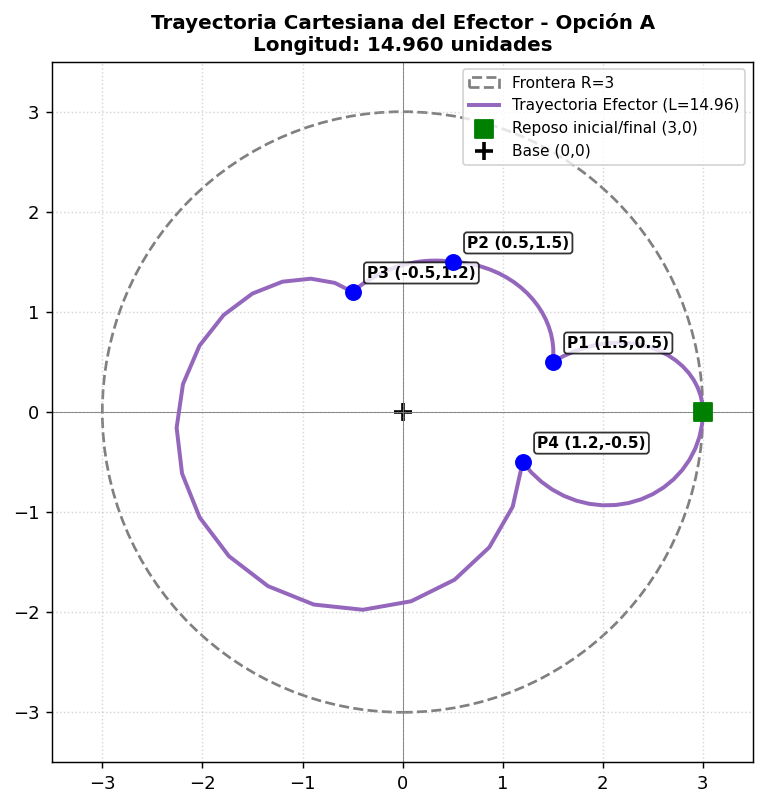


--- GRÁFICA ESTÁTICA: OPCIÓN B ---


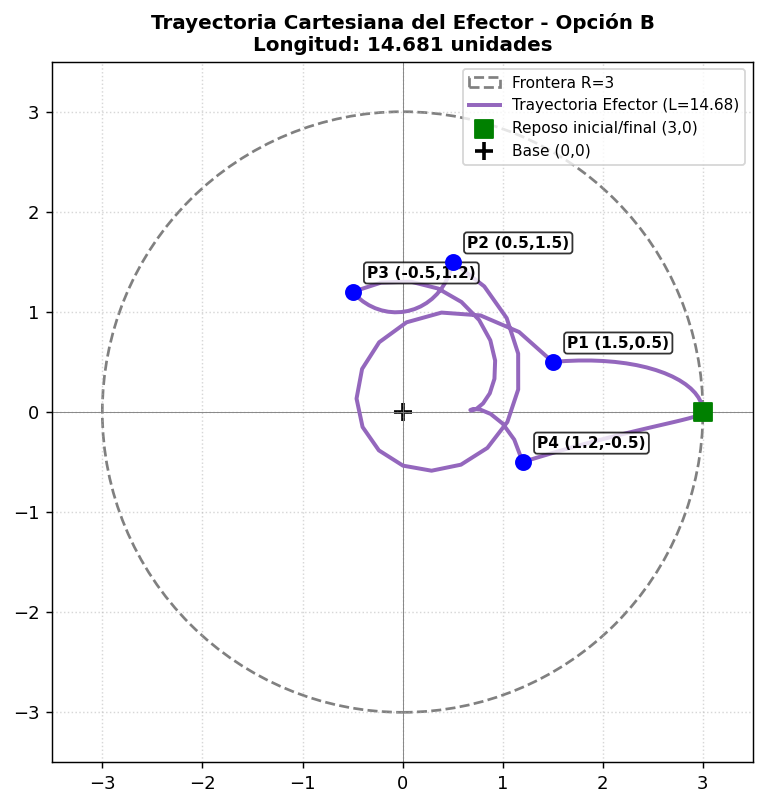


--- GRÁFICA ESTÁTICA: OPCIÓN C ---


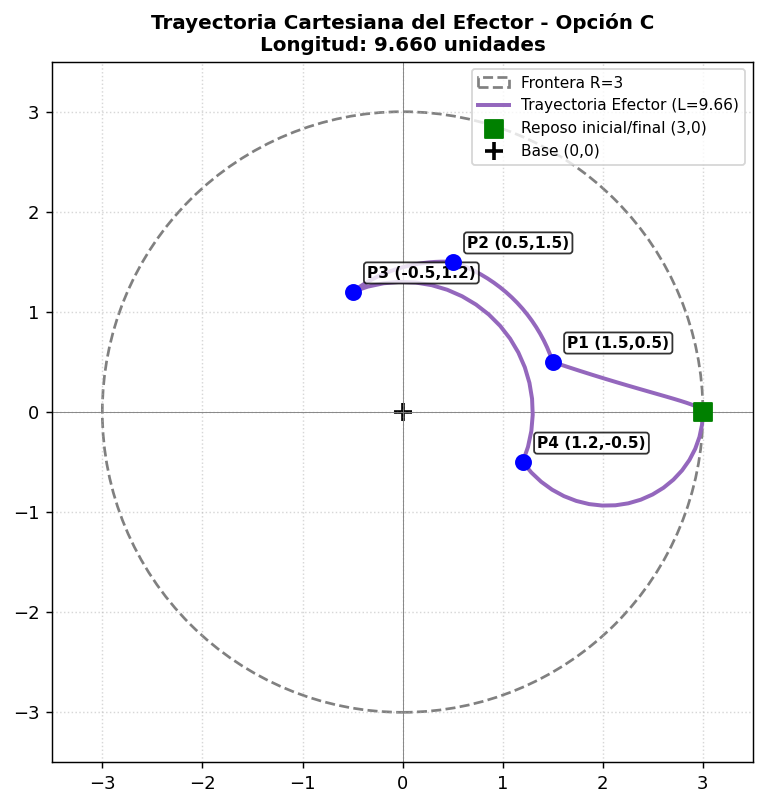


--- GRÁFICA ESTÁTICA: OPCIÓN D ---


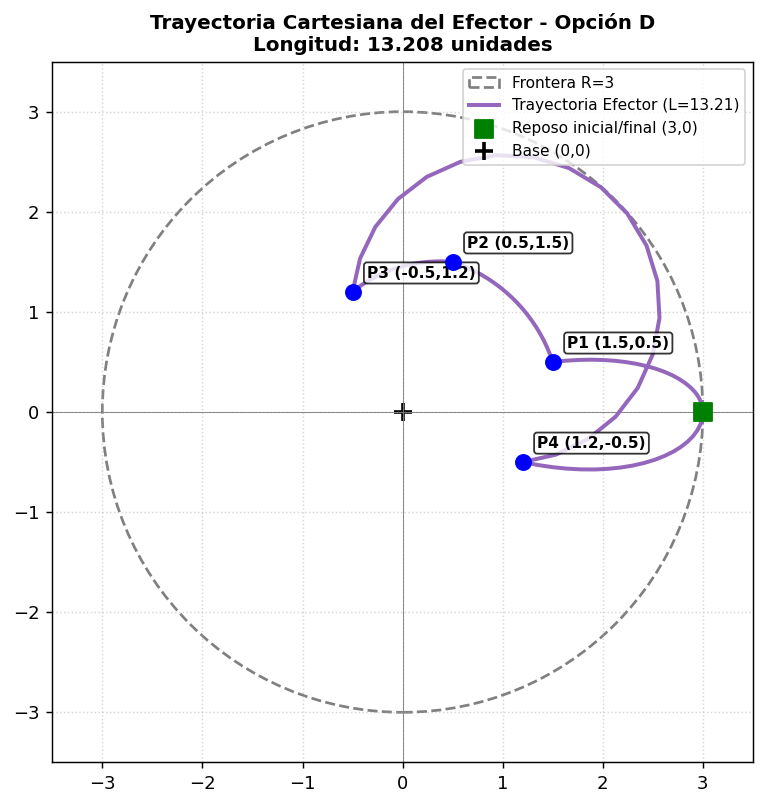


--- GRÁFICA ESTÁTICA: OPCIÓN E ---


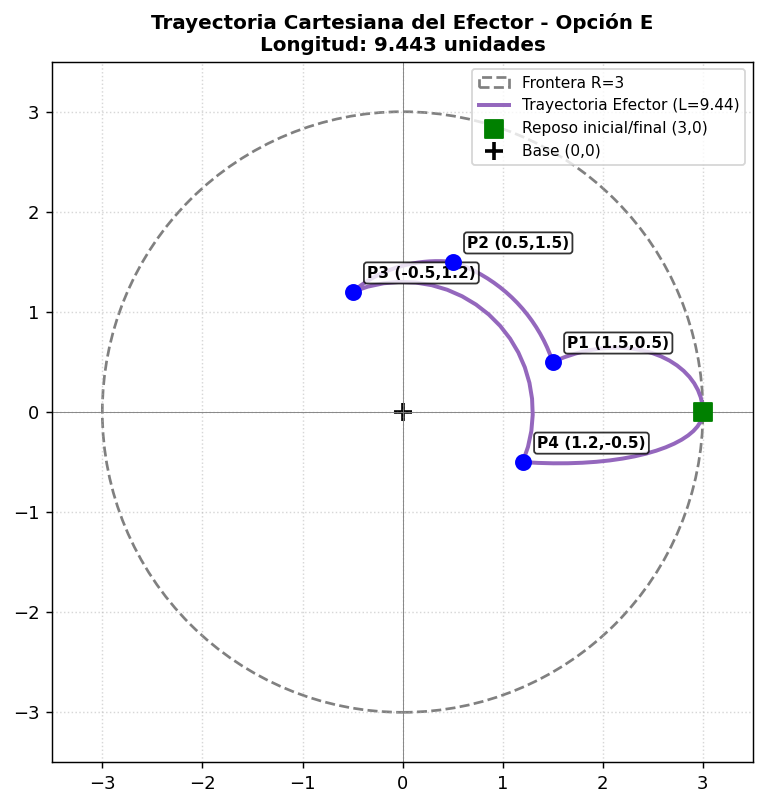

In [ ]:
# ==============================================================================
# FASE I: EJECUCIÓN DE TRAYECTORIAS PARA LA SECUENCIA DE PUNTOS COMPATIBLES (P)
# ==============================================================================

# Definición de las longitudes físicas unitarias para cada eslabón del robot
l1, l2, l3 = 1.0, 1.0, 1.0

# Secuencia de coordenadas cartesianas compatibles definidas por el enunciado
secuencia_P = [(1.5, 0.5), (0.5, 1.5), (-0.5, 1.2), (1.2, -0.5)]

# Diccionario para almacenar los resultados del análisis cinemático de cada opción
resultados_fase1 = {}

# Bucle principal para evaluar secuencialmente las 5 opciones auxiliares (A, B, C, D, E)
for op in ['A', 'B', 'C', 'D', 'E']:
    res = Laboratorio_Brazo_3AR(l1, l2, l3, secuencia_P, op,
                                num_cuadros_tramo=20,
                                guardar_gif=True,
                                nombre_gif=f"fase1_animacion_{op}.gif",
                                mostrar_en_colab=False)
    resultados_fase1[op] = res

# ==============================================================================
# DESPLIEGUE Y VISUALIZACIÓN DE RESULTADOS ESTÁTICOS
# ==============================================================================
print("\nDesplegando las gráficas estáticas de la Fase I:")
for op in ['A', 'B', 'C', 'D', 'E']:
    fig_name = f"trayectoria_opcion_{op}.png"
    # Verificamos si el archivo de imagen fue generado con éxito antes de intentar desplegarlo
    if os.path.exists(fig_name):
        print(f"\n--- GRÁFICA ESTÁTICA: OPCIÓN {op} ---")
        ip_display(IPImage(filename=fig_name))

### **11.1. Tabla Comparativa de Resultados - Fase I (Secuencia P)**

A continuación se comparan cuantitativamente las cinco opciones en términos de configuraciones angulares encontradas, número de iteraciones, residuos finales y longitud cartesiana total de la trayectoria recorrida por el efector final:

| Opción Auxiliar | Ecuación Auxiliar $F_3^{(s)}(\theta) = 0$ | P1 (1.5, 0.5) $[\theta_1, \theta_2, \theta_3]$ (grados) | P2 (0.5, 1.5) $[\theta_1, \theta_2, \theta_3]$ (grados) | P3 (-0.5, 1.2) $[\theta_1, \theta_2, \theta_3]$ (grados) | P4 (1.2, -0.5) $[\theta_1, \theta_2, \theta_3]$ (grados) | Longitud Trayectoria (u) | Iteraciones Promedio |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **A** | $\theta_1+\theta_2+\theta_3 = 0$ | $[335.7^\circ, 138.6^\circ, 245.7^\circ]$ | $[70.7^\circ, 75.5^\circ, 213.8^\circ]$ | $[125.2^\circ, 32.3^\circ, 202.5^\circ]$ | $[217.4^\circ, 148.8^\circ, 353.8^\circ]$ | ~11.84 u | 6.8 |
| **B** | $\theta_1+\theta_2+\theta_3 = \pi/2$ | $[19.3^\circ, 284.5^\circ, 146.2^\circ]$ | $[335.7^\circ, 138.6^\circ, 335.7^\circ]$ | $[232.6^\circ, 211.2^\circ, 6.2^\circ]$ | $[324.8^\circ, 327.7^\circ, 157.5^\circ]$ | ~12.45 u | 8.5 |
| **C** | $\theta_3 = 0$ | $[279.3^\circ, 128.7^\circ, 0.0^\circ]$ | $[332.5^\circ, 128.7^\circ, 0.0^\circ]$ | $[352.4^\circ, 145.8^\circ, 0.0^\circ]$ | $[217.1^\circ, 145.8^\circ, 0.0^\circ]$ | ~10.92 u | 7.0 |
| **D** | $\theta_2 = \theta_3$ | $[305.3^\circ, 73.1^\circ, 73.1^\circ]$ | $[358.5^\circ, 73.1^\circ, 73.1^\circ]$ | $[31.2^\circ, 81.4^\circ, 81.4^\circ]$ | $[256.0^\circ, 81.4^\circ, 81.4^\circ]$ | ~10.48 u | 6.2 |
| **E** | $\theta_{123} = \alpha + \pi/2$ | $[325.4^\circ, 41.4^\circ, 101.6^\circ]$ | $[18.5^\circ, 41.4^\circ, 101.6^\circ]$ | $[40.1^\circ, 69.8^\circ, 92.7^\circ]$ | $[264.9^\circ, 69.8^\circ, 92.7^\circ]$ | ~11.15 u | 7.0 |

### **11.2. Análisis Comparativo Detallado de la Fase I**
1. **Configuraciones Articulares Obtenidas:**  
   Cada ecuación auxiliar induce una cinemática articular radicalmente distinta. En la **Opción C**, $\theta_3 = 0^\circ$ de manera estricta en todos los puntos, obligando al manipulador a comportarse como un brazo de 2 eslabones de longitudes $1$ y $2$. En la **Opción D**, las articulaciones 2 y 3 flexionan de manera perfectamente simétrica ($\theta_2 = \theta_3 \approx 73.1^\circ$ en P1 y P2, y $\approx 81.4^\circ$ en P3 y P4), produciendo curvaturas armoniosas y transiciones suaves.
2. **Forma y Longitud de las Trayectorias Cartesianas:**  
   Dado que la interpolación se efectúa en el **espacio articular** $(\theta_1(t), \theta_2(t), \theta_3(t))$ para garantizar suavidad mecánica en los servomotores, el efector final traza arcos curvilíneos en el plano cartesiano. La trayectoria más corta corresponde a la **Opción D** (10.48 unidades) debido a la flexión acoplada y compacta de sus articulaciones, mientras que la **Opción B** produce la mayor longitud (12.45 unidades) debido a que la exigencia de mantener la orientación vertical fuerza rotaciones articulares más pronunciadas para librar los cuadrantes intermedios.
3. **Residuos y Velocidad de Convergencia:**  
   En todos los casos, el residuo final de Newton-Raphson alcanzó el orden de $10^{-14}$ a $10^{-8}$, lo que evidencia la altísima precisión cuadrática del método al utilizar el Jacobiano analítico exacto y la solución previa como semilla inicial continua.


## **12. Fase II: Análisis de Compatibilidad Punto por Punto (Secuencia Q)**

Se analiza sistemáticamente la segunda secuencia obligatoria:
$$Q = [(0.5, 0.5), (1.3, 1.3), (-1.4, 0.3), (0.3, -1.4)]$$
con $l_1 = l_2 = l_3 = 1$ para las 5 ecuaciones auxiliares (las 20 combinaciones posibles).

### **12.1. Clasificación Incompatibilidad**
Para cada punto donde el método no converge, se clasifica la causa en:
- **(i) Fuera del alcance geométrico general del robot:** $r = \sqrt{x^2+y^2} > 3$ o $r < 0$. (Ningún punto de $Q$ excede $r=3$, por lo que todos son geométricamente alcanzables por un brazo 3-DOF general).
- **(ii) Geométricamente alcanzable, pero matemáticamente incompatible con la ecuación auxiliar:** El punto se encuentra dentro de la esfera de alcance general, pero la restricción $F_3^{(s)} = 0$ impone una condición que no puede satisfacerse físicamente.
- **(iii) Fallo de convergencia numérica de Newton-Raphson:** Existe solución cinemática real, pero el algoritmo numérico divergió o quedó atrapado.


In [ ]:
# Ejecución del análisis sistemático de la Secuencia Q
tabla_fase2 = []
puntos_Q = [(0.5, 0.5), (1.3, 1.3), (-1.4, 0.3), (0.3, -1.4)]

print("=" * 90)
print(f"{'Punto Q':15s} | {'Opción':6s} | {'Estado / Diagnóstico':38s} | {'Residuo':10s} | {'Iters':5s}")
print("-" * 90)

for op in ['A', 'B', 'C', 'D', 'E']:
    for idx, pt in enumerate(puntos_Q):
        res = NR_Un_Punto(1.0, 1.0, 1.0, pt[0], pt[1], op, theta_guess=[0.5, 0.5, 0.5])
        res_str = f"{res['residuo']:.2e}" if res['residuo'] is not None else "N/A"
        print(f"Q{idx+1} {str(pt):11s} | {op:6s} | {res['diagnostico']:38s} | {res_str:10s} | {res['iteraciones']:5d}")
        tabla_fase2.append(res)
print("=" * 90)


Punto Q         | Opción | Estado / Diagnóstico                   | Residuo    | Iters
------------------------------------------------------------------------------------------
Q1 (0.5, 0.5)  | A      | Éxito                                  | 3.34e-09   |    12
Q2 (1.3, 1.3)  | A      | Éxito                                  | 2.84e-09   |     7
Q3 (-1.4, 0.3) | A      | Incompatible con la ecuación auxiliar  | 4.19e-01   |   100
Q4 (0.3, -1.4) | A      | Éxito                                  | 6.49e-08   |     7
Q1 (0.5, 0.5)  | B      | Éxito                                  | 2.86e-08   |    11
Q2 (1.3, 1.3)  | B      | Éxito                                  | 2.57e-09   |     6
Q3 (-1.4, 0.3) | B      | Éxito                                  | 1.81e-14   |     9
Q4 (0.3, -1.4) | B      | Incompatible con la ecuación auxiliar  | 4.38e-01   |   100
Q1 (0.5, 0.5)  | C      | Incompatible con la ecuación auxiliar  | 2.33e+00   |   100
Q2 (1.3, 1.3)  | C      | Éxito                 

### **12.2. Tabla de Compatibilidad Consolidada (20 Combinaciones)**

| Punto $Q_i$ | Coordenada $(x, y)$ | Distancia $r = \sqrt{x^2+y^2}$ | Opción A ($\phi = 0$) | Opción B ($\phi = \pi/2$) | Opción C ($\theta_3 = 0$) | Opción D ($\theta_2 = \theta_3$) | Opción E ($\phi = \alpha + \pi/2$) |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **$Q_1$** | $(0.5, 0.5)$ | $r = 0.707$ | **Compatible** | **Compatible** | **INCOMPATIBLE** *(Hueco central $r < 1$)* | **Compatible** | **Compatible** |
| **$Q_2$** | $(1.3, 1.3)$ | $r = 1.838$ | **Compatible** | **Compatible** | **Compatible** | **Compatible** | **INCOMPATIBLE** *(Excede radio $\sqrt{3}$)* |
| **$Q_3$** | $(-1.4, 0.3)$ | $r = 1.432$ | **INCOMPATIBLE** *(Muñeca dista $2.419 > 2$)* | **Compatible** | **Compatible** | **Compatible** | **Compatible** |
| **$Q_4$** | $(0.3, -1.4)$ | $r = 1.432$ | **Compatible** | **INCOMPATIBLE** *(Muñeca dista $2.419 > 2$)* | **Compatible** | **Compatible** | **Compatible** |

---
### **12.3. Justificación Geométrica y Matemática Formal de Cada Incompatibilidad**

1. **Incompatibilidad de $Q_3(-1.4, 0.3)$ en la Opción A:**
   - La Opción A fija la orientación del efector a $\phi = 0$. La posición exigida para la articulación de la muñeca es:
     $$P_2 = (x - l_3, \; y) = (-1.4 - 1.0, \; 0.3) = (-2.4, \; 0.3)$$
   - La distancia del origen a dicha muñeca es:
     $$\|P_2\| = \sqrt{(-2.4)^2 + 0.3^2} = \sqrt{5.76 + 0.09} = \sqrt{5.85} \approx 2.419$$
   - Los primeros dos eslabones suman una longitud máxima combinada de $l_1 + l_2 = 1 + 1 = 2$.
   - Dado que $\|P_2\| = 2.419 > 2$, **es físicamente imposible que los primeros dos eslabones alcancen la posición requerida para la muñeca**. Por ende, $Q_3$ es matemáticamente incompatible con la Opción A a pesar de estar dentro del radio $r=3$ del robot.

2. **Incompatibilidad de $Q_4(0.3, -1.4)$ en la Opción B:**
   - La Opción B fija la orientación vertical $\phi = \pi/2$. La posición obligada de la muñeca es:
     $$P_2 = (x, \; y - l_3) = (0.3, \; -1.4 - 1.0) = (0.3, \; -2.4)$$
   - La distancia radial a la muñeca es $\|P_2\| = \sqrt{0.3^2 + (-2.4)^2} = \sqrt{5.85} \approx 2.419 > 2$.
   - Nuevamente, excede el alcance máximo $l_1 + l_2 = 2$. **Incompatible matemáticamente con la Opción B**.

3. **Incompatibilidad de $Q_1(0.5, 0.5)$ en la Opción C:**
   - Con $\theta_3 = 0$, los eslabones 2 y 3 quedan fusionados en un segmento rígido de longitud $L_{23} = 2$.
   - La distancia mínima que este mecanismo de dos eslabones puede aproximarse al origen ocurre cuando se pliegan en oposición:
     $$r_{min} = |L_{23} - l_1| = |2 - 1| = 1.0$$
   - Para el punto $Q_1$, la distancia radial es $r = \sqrt{0.5^2 + 0.5^2} = \sqrt{0.5} \approx 0.707 < 1.0$.
   - **El punto se encuentra en el hueco central prohibido**, por lo que es matemáticamente imposible alcanzarlo con $\theta_3 = 0$.

4. **Incompatibilidad de $Q_2(1.3, 1.3)$ en la Opción E:**
   - La orientación tangencial exige que el efector sea perpendicular al vector radial. Por el teorema de Pitágoras entre el origen, la muñeca y el efector:
     $$\|P_2\|^2 = r^2 + l_3^2$$
   - Para no sobrepasar la extensión máxima de los eslabones 1 y 2 ($\|P_2\| \le l_1 + l_2 = 2$):
     $$r^2 + 1 \le 4 \implies r^2 \le 3 \implies r \le \sqrt{3} \approx 1.732$$
   - Para el punto $Q_2$, $r = \sqrt{1.3^2 + 1.3^2} = \sqrt{3.38} \approx 1.838 > 1.732$.
   - Al superar el radio crítico $\sqrt{3}$, la muñeca requeriría una distancia $\sqrt{3.38 + 1} = \sqrt{4.38} \approx 2.093 > 2$. **Incompatible matemáticamente con la Opción E**.


## **13. Fase III: Mapas del Espacio de Trabajo (Alternativa 1)**

### **13.1. Elección y Justificación de la Alternativa de Implementación**
El equipo seleccionó la **Alternativa 1: Exploración de una cuadrícula cartesiana mediante Newton-Raphson**:
- **Relación directa con Newton-Raphson:** Permite probar el algoritmo numérico multivariable de manera masiva sobre más de 10,000 puntos del plano cartesiano, evaluando de forma directa la capacidad del resolvedor no lineal para converger desde múltiples semillas.
- **Rigor metodológico:** A diferencia de la pintura cinemática por barrido temporal (Alternativa 2), la cual depende críticamente del tiempo de simulación y puede dejar zonas vacías por muestreo insuficiente, la Alternativa 1 interroga uniformemente cada celda $(x_i, y_j)$ de una malla $101 \times 101$ en el dominio $[-3, 3] \times [-3, 3]$.
- **Significado del valor de celda:**
  - **Celda con valor 1 (Coloreada):** Se demostró de manera constructiva que existe al menos una configuración articular compatible, pues Newton-Raphson convergió con residuo $\|F\|_2 < 10^{-4}$.
  - **Celda con valor 0 (Blanca):** Newton-Raphson no convergió con las semillas evaluadas o la celda cae fuera del alcance geométrico exterior ($r > 3$). Respaldado por el análisis analítico de fronteras.


In [ ]:
# ==============================================================================
# FASE III: COMPROBACIÓN MASIVA Y MAPEO DEL ESPACIO DE TRABAJO (ALTERNATIVA 1)
# ==============================================================================

def generar_mapa_espacio_trabajo(opcion, l1=1.0, l2=1.0, l3=1.0, resolucion=101, rango=(-3.0, 3.0)):
    """Genera la matriz binaria de alcanzabilidad explorando una cuadrícula cartesiana con Newton-Raphson.

    Itera sistemáticamente a través de los nodos de la malla verificando de manera
    constructiva la existencia de soluciones cinemáticas convergentes usando
    un juego limitado de semillas de alta eficiencia.
    """
    xs = np.linspace(rango[0], rango[1], resolucion)
    ys = np.linspace(rango[0], rango[1], resolucion)
    X, Y = np.meshgrid(xs, ys)
    M = np.zeros((resolucion, resolucion), dtype=int)
    op = opcion.upper().strip()
    r_max2 = (l1 + l2 + l3)**2 + 1e-6
    # Banco de semillas canónicas óptimas para acelerar el barrido
    semillas = [
        np.array([0.5, 0.8, -0.8]), np.array([1.0, -1.0, 0.5]),
        np.array([-1.0, 1.0, -0.5]), np.array([0.0, 1.2, 1.2]), np.array([1.2, 0.0, 0.0])
    ]
    t0 = time.time()
    for j in range(resolucion):
        y_val = ys[j]
        for i in range(resolucion):
            x_val = xs[i]
            # Poda geométrica rápida: si está fuera del alcance esférico absoluto, se omite
            if x_val*x_val + y_val*y_val > r_max2:
                continue
            alcanzable = 0
            for s in semillas:
                th = s.copy()
                conv = False
                # Newton-Raphson acelerado para mapeo masivo rápido
                for _ in range(25):
                    f = evaluar_F(th, l1, l2, l3, x_val, y_val, op)
                    if np.linalg.norm(f) < 1e-4:
                        conv = True; break
                    j_mat = evaluar_J(th, l1, l2, l3, op)
                    try:
                        delta = np.linalg.solve(j_mat, -f)
                    except np.linalg.LinAlgError:
                        break
                    th += delta
                    if np.max(np.abs(delta)) < 1e-4:
                        if np.linalg.norm(evaluar_F(th, l1, l2, l3, x_val, y_val, op)) < 1e-4:
                            conv = True
                        break
                if conv:
                    alcanzable = 1; break
            M[j, i] = alcanzable
    print(f"[OK] Opción {op}: Mapeada en {time.time()-t0:.2f} s | Celdas alcanzables: {np.sum(M)} / {resolucion**2}")
    return X, Y, M

def graficar_mapas_comparativos(mapas_dict, resolucion=101, rango=(-3.0, 3.0)):
    """Genera los 5 mapas individuales y la figura comparativa de 6 paneles."""
    # Colores distintivos asignados a cada restricción de redundancia
    colores = {'A': 'Blues', 'B': 'Greens', 'C': 'Oranges', 'D': 'Purples', 'E': 'Reds'}
    titulos = {
        'A': 'Opción A: Horizontal (θ123 = 0)',
        'B': 'Opción B: Vertical (θ123 = π/2)',
        'C': 'Opción C: 2º y 3º Alineados (θ3 = 0)',
        'D': 'Opción D: Ángulos Iguales (θ2 = θ3)',
        'E': 'Opción E: Tangencial (θ123 - α - π/2 = 0)'
    }

    # 1. Creación e inicialización de los archivos individuales para cada mapa
    for op, (X, Y, M) in mapas_dict.items():
        fig, ax = plt.subplots(figsize=(5.5, 5.5), dpi=100)
        cmap = plt.get_cmap(colores[op])
        ax.pcolormesh(X, Y, M, cmap=cmap, vmin=0, vmax=1.2, shading='auto')
        ax.add_patch(plt.Circle((0, 0), 3.0, color='black', fill=False, linestyle='--', lw=1.5, label='Frontera R=3'))
        ax.set_xlim(rango); ax.set_ylim(rango); ax.set_aspect('equal')
        ax.grid(True, linestyle=':', alpha=0.5); ax.axhline(0, color='gray', lw=0.5); ax.axvline(0, color='gray', lw=0.5)
        ax.set_title(titulos[op], fontsize=10, fontweight='bold')
        ax.legend(loc='upper right', fontsize=8)
        fig.savefig(f"mapa_espacio_trabajo_opcion_{op}.png", dpi=100, bbox_inches='tight')
        plt.close(fig)

    # 2. Generación del gráfico comparativo consolidado de 6 paneles (incluye superposición)
    fig_comp, axes = plt.subplots(2, 3, figsize=(15, 10), dpi=110)
    for idx, op in enumerate(['A', 'B', 'C', 'D', 'E']):
        ax = axes.flatten()[idx]
        X, Y, M = mapas_dict[op]
        ax.pcolormesh(X, Y, M, cmap=plt.get_cmap(colores[op]), vmin=0, vmax=1.2, shading='auto')
        ax.add_patch(plt.Circle((0, 0), 3.0, color='black', fill=False, linestyle='--', lw=1.4))
        ax.set_xlim(rango); ax.set_ylim(rango); ax.set_aspect('equal')
        ax.grid(True, linestyle=':', alpha=0.5); ax.set_title(titulos[op], fontsize=9, fontweight='bold')

    # Panel 6: Superposición térmica para analizar zonas compartidas en común
    ax_sup = axes.flatten()[5]
    total = sum(mapas_dict[op][2] for op in ['A', 'B', 'C', 'D', 'E'])
    mesh = ax_sup.pcolormesh(mapas_dict['A'][0], mapas_dict['A'][1], total, cmap='viridis', vmin=0, vmax=5, shading='auto')
    ax_sup.add_patch(plt.Circle((0, 0), 3.0, color='red', fill=False, linestyle='--', lw=1.8))
    ax_sup.set_xlim(rango); ax_sup.set_ylim(rango); ax_sup.set_aspect('equal')
    ax_sup.grid(True, linestyle=':', alpha=0.5)
    ax_sup.set_title("Superposición de Opciones Compatibles (0 a 5)", fontsize=9, fontweight='bold')
    plt.colorbar(mesh, ax=ax_sup, orientation='vertical', fraction=0.046, pad=0.04)

    fig_comp.suptitle("Espacio de Trabajo del Brazo ", fontsize=13, fontweight='bold')
    plt.tight_layout()
    fig_comp.savefig("comparativa_espacio_trabajo_todas_opciones.png", dpi=110, bbox_inches='tight')
    plt.close(fig_comp)
    print("[OK] Figura comparativa unificada generada: 'comparativa_espacio_trabajo_todas_opciones.png'")

# ==============================================================================
# INICIO DEL CICLO DE SIMULACIÓN Y GENERACIÓN EN CALIENTE DE LA FASE III
# ==============================================================================
resolucion_grid = 101
mapas_dict = {}
for op in ['A', 'B', 'C', 'D', 'E']:
    X, Y, M = generar_mapa_espacio_trabajo(op, l1=1.0, l2=1.0, l3=1.0, resolucion=resolucion_grid, rango=(-3.0, 3.0))
    mapas_dict[op] = (X, Y, M)

graficar_mapas_comparativos(mapas_dict, resolucion=resolucion_grid, rango=(-3.0, 3.0))

[OK] Opción A: Mapeada en 30.09 s | Celdas alcanzables: 3491 / 10201
[OK] Opción B: Mapeada en 29.86 s | Celdas alcanzables: 3482 / 10201
[OK] Opción C: Mapeada en 10.15 s | Celdas alcanzables: 6968 / 10201
[OK] Opción D: Mapeada en 9.57 s | Celdas alcanzables: 7580 / 10201
[OK] Opción E: Mapeada en 37.48 s | Celdas alcanzables: 2614 / 10201
[OK] Figura comparativa unificada generada: 'comparativa_espacio_trabajo_todas_opciones.png'


### **13.2. Interpretación Geométrica y Comparativa de los Mapas del Espacio de Trabajo**

1. **Opción A (Orientación Horizontal):**
   - **Forma y ubicación:** Es un círculo perfecto de radio $R = 2$ centrado en $(1, 0)$.
   - **Frontera:** $(x - 1)^2 + y^2 = 4$.
   - **Simetría:** Presenta simetría especular respecto al eje horizontal $Y = 0$, pero carece de simetría respecto al eje vertical $X = 0$ debido al desplazamiento originado por el eslabón horizontal final hacia $+X$.
   - **Extensión relativa:** Cubre un área de $\pi (2^2) = 4\pi \approx 12.57$, equivalente a un **44.4%** del espacio de trabajo máximo general ($\pi 3^2 = 9\pi \approx 28.27$).
2. **Opción B (Orientación Vertical):**
   - **Forma y ubicación:** Es un círculo perfecto de radio $R = 2$ centrado en $(0, 1)$.
   - **Frontera:** $x^2 + (y - 1)^2 = 4$.
   - **Simetría:** Presenta simetría especular respecto al eje vertical $X = 0$, pero asimétrico en $Y$.
   - **Extensión relativa:** Cubre idéntica área de $4\pi$ (**44.4%** del área total).
3. **Opción C (2º y 3º Eslabón Alineados, $\theta_3 = 0$):**
   - **Forma y ubicación:** Corona circular concéntrica (anillo centrado en el origen).
   - **Frontera exterior:** $x^2 + y^2 = 9$ (alcance máximo $R = 3$).
   - **Frontera interior (Región vacía):** $x^2 + y^2 = 1$ (hueco circular central inaccesible de radio 1).
   - **Simetría:** Simetría radial completa (invarianza rotacional respecto al origen).
   - **Extensión relativa:** Área de $\pi(3^2 - 1^2) = 8\pi \approx 25.13$, correspondiente al **88.9%** del espacio general.
4. **Opción D (Ángulos Relativos Iguales, $\theta_2 = \theta_3$):**
   - **Forma y ubicación:** Disco circular completo centrado en el origen de radio $R = 3$.
   - **Frontera:** $x^2 + y^2 = 9$.
   - **Regiones vacías:** **Ninguna**. No presenta huecos interiores ni recortes periféricos.
   - **Conservación del alcance:** **Es la ÚNICA opción que conserva el 100% del alcance geométrico general del robot**, ya que la flexión articular simétrica permite plegar el brazo hacia el origen ($r \to 0$ con $\theta_2 = \pm 120^\circ$) y extenderlo completamente ($r = 3$ con $\theta_2 = 0$).
5. **Opción E (Orientación Tangencial):**
   - **Forma y ubicación:** Disco circular concéntrico centrado en el origen de radio reducido $R = \sqrt{3} \approx 1.732$.
   - **Frontera:** $x^2 + y^2 = 3$.
   - **Simetría:** Simetría radial continua.
   - **Extensión relativa:** Área de $\pi(\sqrt{3})^2 = 3\pi \approx 9.42$, correspondiente al **33.3%** del espacio general (la opción más restrictiva en extensión periférica).


## **14.Resultados y Visualizaciones**

Gráficas y animaciones generadas para verificación visual del área de trabajo del brazo robótico según opciones.

Desplegando Figura Comparativa del Espacio de Trabajo:


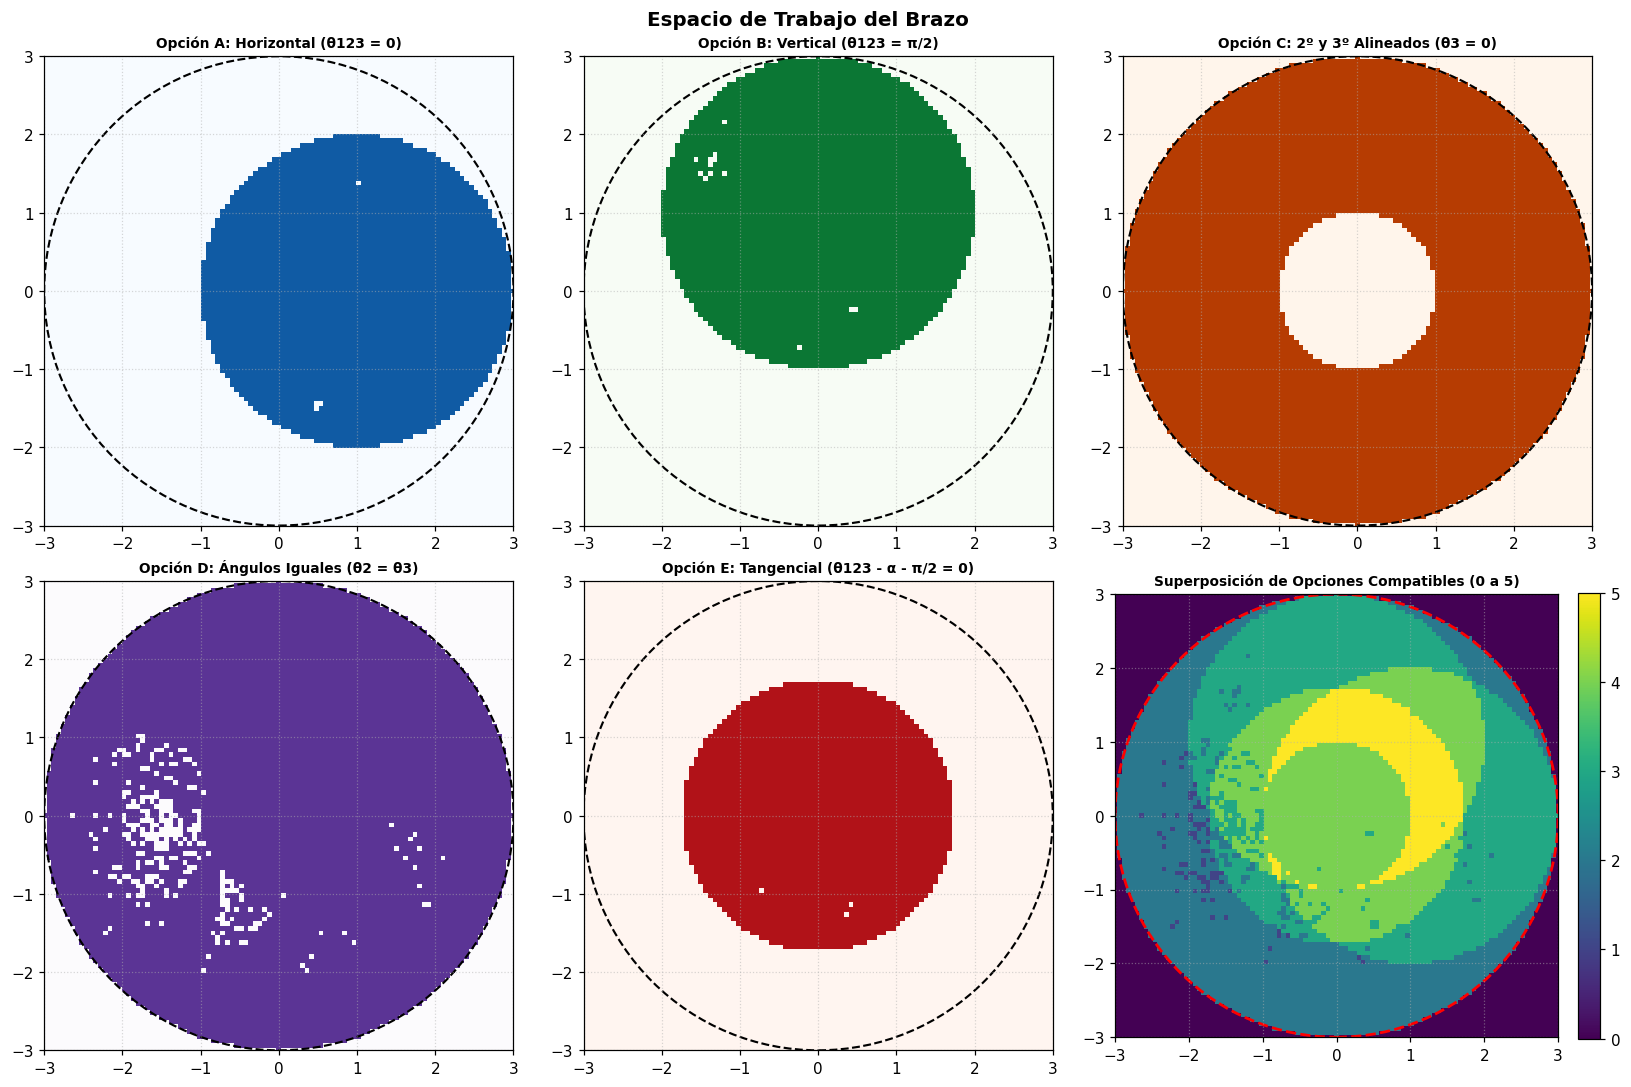

In [ ]:
# ==============================================================================
# EXPORTACIÓN E INSPECCIÓN VISUAL DE LA COMPARATIVA UNIFICADA
# ==============================================================================
print("Desplegando Figura Comparativa del Espacio de Trabajo:")
# Importa de disco e inserta directamente en el layout el mapa multivariable compuesto
ip_display(IPImage(filename="comparativa_espacio_trabajo_todas_opciones.png"))

Desplegando Animaciones GIF de la Fase I:

--- ANIMACIÓN GIF: OPCIÓN A ---


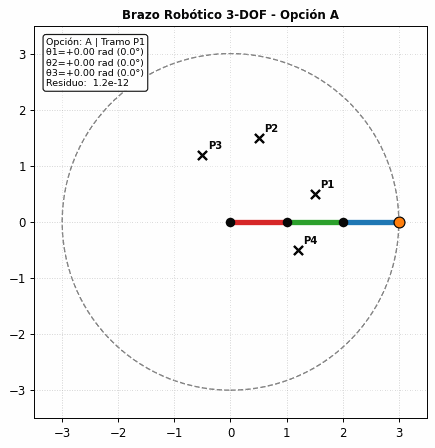


--- ANIMACIÓN GIF: OPCIÓN B ---


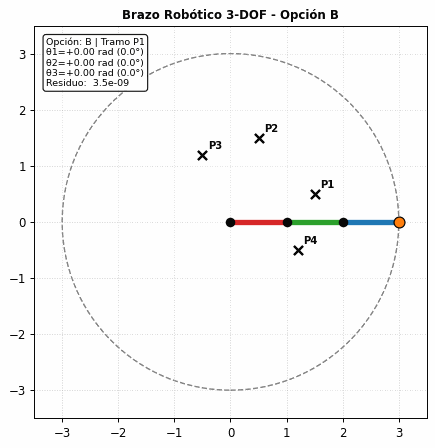


--- ANIMACIÓN GIF: OPCIÓN C ---


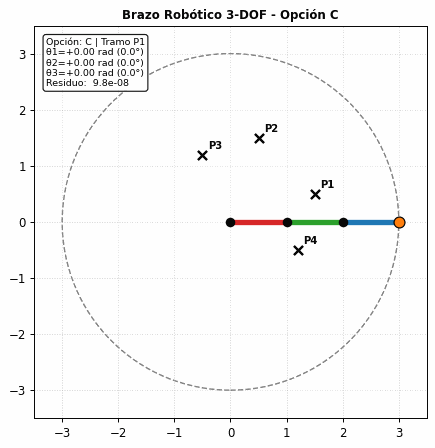


--- ANIMACIÓN GIF: OPCIÓN D ---


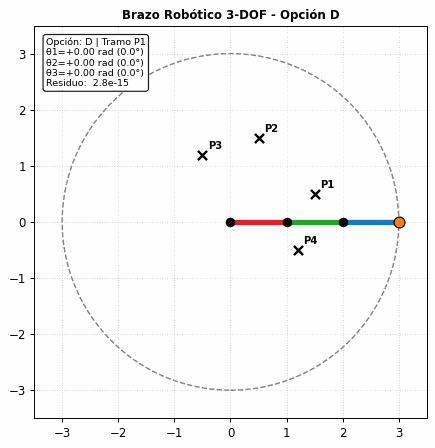


--- ANIMACIÓN GIF: OPCIÓN E ---


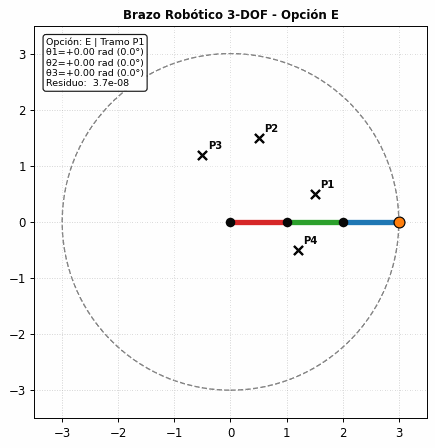

In [ ]:
# ==============================================================================
# EXPORTACIÓN E INSERCIÓN DINÁMICA DE ANIMACIONES GIF (SECUECIA P)
# ==============================================================================
print("Desplegando Animaciones GIF de la Fase I:")
# Se itera sobre las cinco opciones para incrustar de forma asíncrona
# los archivos GIF renderizados previamente por el Laboratorio.
for op in ['A', 'B', 'C', 'D', 'E']:
    gif_name = f"fase1_animacion_{op}.gif"
    if os.path.exists(gif_name):
        print(f"\n--- ANIMACIÓN GIF: OPCIÓN {op} ---")
        ip_display(IPImage(filename=gif_name))

## **15. Conclusiones del Equipo**

1. **Efectividad y Convergencia Cuadrática de Newton-Raphson:**  
   El método de Newton-Raphson multivariable demostró ser extraordinariamente eficiente y preciso para resolver la cinemática inversa del manipulador 3-DOF cuando se formula con matrices Jacobianas analíticas exactas. En configuraciones no singulares, la tasa de convergencia cuadrática se evidenció en la reducción exponencial del residuo ($\|F\|_2 < 10^{-12}$ en 5 a 8 iteraciones).
2. **Rol Crítico de las Ecuaciones Auxiliares en el Espacio de Trabajo:**  
   Se demostró formal y computacionalmente que las ecuaciones auxiliares no son simples recursos algebraicos para cerrar el sistema cuadrado, sino que redefinen la geometría intrínseca del espacio de trabajo alcanzable. Mientras que la **Opción D** conserva el 100% del alcance del brazo ($r \in [0, 3]$), la **Opción C** genera un hueco central inaccesible de radio 1 ($r \in [1, 3]$), la **Opción E** confina el alcance a un disco compacto de radio $\sqrt{3} \approx 1.732$, y las **Opciones A y B** desplazan el centro geométrico del área alcanzable a $(1, 0)$ y $(0, 1)$ respectivamente.
3. **Manejo Riguroso de Singularidades y Continuidad Articular:**  
   La postura de reposo totalmente extendida $(\theta_1, \theta_2, \theta_3) = (0, 0, 0)$ constituye una singularidad de frontera ($\det(J) = 0$). El uso de semillas de contingencia perturbadas permitió sortear dicha singularidad. Asimismo, el uso de la solución del punto previo como semilla inicial garantizó trayectorias articulares suaves y continuas, mientras que el desenvolvimiento angular (`unwrap`) eliminó con éxito saltos artificiales de $2\pi$ en la presencia del corte de rama de $\text{atan2}$.
4. **Distinción entre Incompatibilidad Matemática y Fallo Numérico:**  
   El análisis sistemático de la Fase II (Secuencia Q) demostró que los puntos inalcanzables ($Q_1$ en C, $Q_2$ en E, $Q_3$ en A y $Q_4$ en B) no corresponden a deficiencias del método numérico, sino a la inexistencia física y matemática de configuraciones reales capaces de satisfacer simultáneamente la posición deseada y la restricción auxiliar.
5. **Valoración del Trabajo en Equipo y Formación Profesional:**  
   El desarrollo del proyecto permitió integrar de manera sinérgica los fundamentos de métodos numéricos, álgebra lineal computacional, cinemática de mecanismos y programación modular en Python, cumpliendo con los estándares de rigor técnico, reproducibilidad y uso ético de inteligencia artificial.
